# Will It Fit? Predicting Clothing Fit Feedback on ModCloth
**CSE 158/258 — Assignment 2**

**Task.** Given a customer, a *product* (an item in a specific size) and whatever the customer has told the store about their body, predict whether they will report that the product runs **small**, **fit**s, or runs **large**.

This notebook accompanies our video presentation. It is meant to be read as-is: every output below comes from a single top-to-bottom run with fixed random seeds.

### TL;DR
* **Accuracy is the wrong metric:** always answering "fit" already scores 68.6%. We use **average AUC** (primary), **macro-F1** and the course's **balanced error rate (BER)**.
* **Leakage matters:** the review text, `length` and `quality` are written *after* the customer receives the item. Using them gives AUC ≈ 0.87, while the honest pre-purchase task tops out around **0.72–0.73**.
* **Our model:** an ordinal "true-size" latent factor model (after Sembium et al. 2017 and Misra et al. 2018) extended with body measurements and a learned **fit tolerance**. The tolerance alone adds ≈ +0.04 AUC over the classic true-size model.
* **Honest comparison:** our model is statistically tied with strong simple baselines (logistic regression with id biases, boosted trees). An ensemble of the three scores highest: it is significantly better than either linear/latent model on its own, but within noise of the boosted trees.
* **Fairness:** larger-size customers get 20–30% more misfits, but our models are *not* less accurate for them (equal AUC, no higher BER, and their misfit risk is predicted correctly). Following the course's ethics lecture, which uses ModCloth as a case study, we frame this as an error-parity check.
* **Validity checks:** we verify the gradients numerically, show that the learned sizes track the catalog, and break results down by cold-start customers. Our text baseline matches published work almost exactly (0.790 accuracy). We also show that good fit *prediction* does not yet give good size *recommendation*, because the feedback suffers from selection bias.

### Contents
1. [The predictive task](#sec1): inputs/outputs, metrics, baselines, validity plan
2. [Exploratory analysis & pre-processing](#sec2)
3. [Modeling](#sec3): baselines B0–B2, models M1–M6, Setting B text models
4. [Evaluation](#sec4): results, significance, ROC, cold start, fairness across body sizes, validity checks, ablation, what we tried and left out, recommendation check
5. [Related work & discussion](#sec5)

### How to run
* Place `modcloth_final_data.json.gz` in `data/raw/` (relative to the repo root) and run this notebook from `src/`, like `prepare_data.ipynb`.
* Requirements: `numpy pandas scikit-learn scipy matplotlib seaborn` (plus `jinja2` for coloured tables; the notebook falls back to plain tables without it). No GPU needed.
* Full run time ≈ 6 minutes on a laptop CPU. The slowest steps are the hyperparameter searches for M2, M4 and the text model.

In [1]:
# --- Imports & global settings -------------------------------------------------------------
import gzip, json, re, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse
from scipy.stats import spearmanr
from sklearn.model_selection import train_test_split, KFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score, roc_curve,
                             confusion_matrix, classification_report)

warnings.filterwarnings("ignore")          # silence sklearn convergence / pandas future warnings in the export
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 3)
SEED = 42                                  # same seed as prepare_data.ipynb -> identical splits
np.random.seed(SEED)
CLASSES = ["small", "fit", "large"]        # label order = ordinal order (0 < 1 < 2)

def pretty(df, precision=4, gradient=None):
    """Formatted table for display. Uses pandas Styler (needs jinja2) and falls back to a plain DataFrame."""
    try:
        import jinja2  # noqa: F401  (Styler.to_html requires it)
        s = df.style.format(precision=precision)
        return s.background_gradient(subset=gradient, cmap="Greens") if gradient else s
    except ImportError:
        return df.round(precision)

---
<a id="sec1"></a>
# 1. The predictive task

**Inputs.** For each purchase+review we know the customer (`user_id`), the parent item (`item_id`), the size they bought (`size`), the item's `category`, and any body measurements the customer gave ModCloth (height, bust, waist, hips, bra band, cup size, shoe size/width).

**Output.** `fit` ∈ {small, fit, large}: an **ordinal** 3-class label (small < fit < large), read as "the product is too small / right / too large *for this customer*".

**Why it matters.** This is the core of *size recommendation*. If we can predict the fit feedback for every size of an item, we can recommend the size most likely to fit, and bad fit is a leading cause of costly returns in online clothing retail.

**Two settings, to avoid leakage.** A review contains more than the `fit` label. It also has a `length` rating ("slightly long"…), a `quality` rating (stars) and free text ("runs small, size up!"). All of these are written **after** the customer has worn the item, so a real size recommender **cannot** use them. We therefore study:

* **Setting A: pre-purchase (main task).** Only customer, product and measurements. This is the realistic size-recommendation problem studied by Misra et al. (2018).
* **Setting B: post-hoc (upper bound).** Also uses the review text, `length` and `quality`. It answers a different question ("can we read the fit label from what the customer wrote?"), studied by Baier (2019). We report it only to show how much signal sits in the review, and **never compare B numbers with A numbers as if they were competitors.**

**Evaluation metrics.** The label is imbalanced (≈69% "fit"), so **accuracy is misleading**: always answering "fit" scores 68.6%.
* **Average AUC** (one-vs-rest ROC AUC, averaged over the 3 classes) is the **primary metric**. It is the fraction of (positive, negative) pairs that the model orders correctly: 1.0 is perfect and 0.5 is random. As the course's recommendation lecture puts it, AUC rewards *ordering things correctly* rather than hitting an arbitrary threshold. It is insensitive to class imbalance, and ranking is exactly what a size recommender needs ("which size is most likely to fit?"). Misra et al. also report an "average AUC", although their exact protocol may differ from ours (see Section 5).
* **Macro-F1** is the secondary metric. It forces the model to actually *predict* the rare small/large classes. Turning probabilities into labels needs a decision rule, so for **every** model we pick per-class weights on the **validation** set (`tune_weights`, below). The same procedure applies to every model, so the comparison is fair.
* **Balanced error rate (BER)**, the course's metric for imbalanced classification: BER = ½(FPR + FNR) for two classes, i.e. the average of the per-class error rates. Its multi-class generalization is the mean over classes of (1 − recall of that class) = 1 − balanced accuracy. A naive classifier scores ½ with two classes and **⅔ with our three**; a perfect one scores 0. BER is computed from the same predicted labels as macro-F1.
* **Accuracy** is reported for completeness only.

**Baselines.** Trivial: always "fit"; random by class prior. Non-trivial: each product's smoothed empirical fit distribution ("does this product run small?"); logistic regression on measurements (plain and with balanced class weights); logistic regression with user/item/product biases.

**How we assess validity.** (a) All hyperparameters are tuned on validation, and the test set is used once. (b) Paired bootstrap confidence intervals test whether differences are real. (c) Results are broken down by cold-start vs. returning customers, and by body size (a fairness check). (d) Learned parameters are checked for meaning (do learned "true sizes" follow the catalog sizes?). (e) Hand-written gradients are checked numerically. (f) An ablation study and a check against a published number (Setting B).

---
<a id="sec2"></a>
# 2. Exploratory analysis, data collection & pre-processing

**Where the data comes from.** The ModCloth dataset was released by Misra, Wan & McAuley (RecSys 2018) together with a RentTheRunway dataset, and is distributed on Julian McAuley's dataset page. ModCloth is an online women's clothing retailer. The data was collected from product reviews, where customers leave a fit rating (small/fit/large), a length rating, a quality rating and optional text; the reviewer's self-reported body measurements are shown alongside. The data was built for studying **product size recommendation / fit prediction**.

Each line of the gzipped file is one JSON review.

In [2]:
def load_data(path):
    """Read the gzipped JSON-lines file into a DataFrame (one row per review)."""
    rows = []
    with gzip.open(path, "rt", encoding="utf-8") as f:
        for line in f:
            if line.strip():
                rows.append(json.loads(line))
    return pd.DataFrame(rows)

raw = load_data("../data/raw/modcloth_final_data.json.gz")
print(f"{len(raw):,} reviews x {raw.shape[1]} columns")
raw.head(3).T

82,790 reviews x 18 columns


,0,1,2
item_id,123373,123373,123373
waist,29,31,30
size,7,13,7
quality,5.0,3.0,2.0
cup size,d,b,b
hips,38,30,NaN
bra size,34,36,32
category,new,new,new
bust,36,NaN,NaN
height,5ft 6in,5ft 2in,5ft 7in


### Missingness
Measurements are optional, so many are mostly missing: waist (96.5% missing) and bust (85.7%) are nearly unusable, while bra size, cup size and height are present for over 90% of reviews. **Missingness is itself informative** (it reflects which customers fill in their profile), so instead of dropping rows we impute and add explicit missing-indicator features.

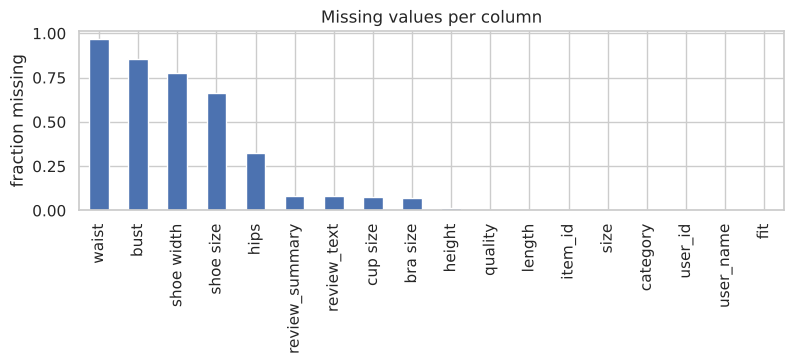

In [3]:
miss = raw.isna().mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 3.8))
miss.plot.bar(ax=ax, color="#4C72B0")
ax.set_ylabel("fraction missing"); ax.set_title("Missing values per column")
plt.tight_layout(); plt.show()

### Label distribution
The label is imbalanced but **symmetric**: "small" and "large" are each ≈16%. Any model must beat 68.6% accuracy just to equal the majority guess, which is why we rely on AUC and macro-F1.

In [4]:
dist = raw["fit"].value_counts().reindex(CLASSES)
pd.DataFrame({"count": dist, "fraction": (dist / dist.sum()).round(3)})

,count,fraction
fit,,
small,12974,0.157
fit,56757,0.686
large,13059,0.158


### Sparsity: the central challenge
**Two-thirds of customers have exactly one review**, and items have a median of only 3 reviews. A *product* in Misra et al.'s sense (item × size) is sparser still. Pure collaborative filtering will struggle for most customers, which motivates combining latent factors with **content features** (measurements).

customers: 47,958 | items: 1,378 | products (item x size): 5,005
customers with exactly 1 review: 66.5%  (they wrote 38.5% of all reviews)
median reviews per item: 3 | per product: 2


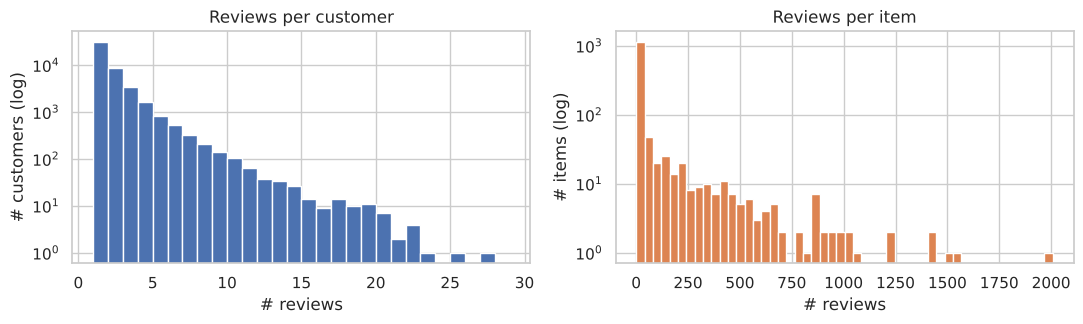

In [5]:
ucount = raw["user_id"].value_counts()
icount = raw["item_id"].value_counts()
pcount = raw.groupby(["item_id", "size"]).size()
print(f"customers: {len(ucount):,} | items: {len(icount):,} | products (item x size): {len(pcount):,}")
print(f"customers with exactly 1 review: {(ucount == 1).mean():.1%}  "
      f"(they wrote {(raw.user_id.map(ucount) == 1).mean():.1%} of all reviews)")
print(f"median reviews per item: {icount.median():.0f} | per product: {pcount.median():.0f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].hist(ucount, bins=np.arange(1, 30), color="#4C72B0"); axes[0].set_yscale("log")
axes[0].set_title("Reviews per customer"); axes[0].set_xlabel("# reviews"); axes[0].set_ylabel("# customers (log)")
axes[1].hist(icount, bins=50, color="#DD8452"); axes[1].set_yscale("log")
axes[1].set_title("Reviews per item"); axes[1].set_xlabel("# reviews"); axes[1].set_ylabel("# items (log)")
plt.tight_layout(); plt.show()

### Pre-processing
* `height` is a string like "5ft 6in" → parsed to inches.
* `bra size`, `bust`, `hips`, `waist`, `shoe size` → numeric (some `bust` values are ranges such as "37-39"; we take the midpoint).
* `cup size` → ordinal code (aa < a < b < … < k).
* Missing numeric values → filled with the **training** median, plus a binary missing-indicator per column.
* `review_summary` + `review_text` → one text field (Setting B only).
* A **product** = (`item_id`, `size`) pair, following Misra et al.

**Split.** We reproduce the split of our shared `prepare_data.ipynb` exactly: random 80/10/10, stratified by the label, `random_state=42`. This is also the protocol of Misra et al. (random 80:10:10). Statistics above describe the whole dataset; **every analysis from here on that could influence a modeling decision uses the training split only**, so the test set stays untouched.

In [6]:
def parse_height(h):
    """'5ft 6in' -> 66 (inches); NaN if missing or unparseable."""
    if not isinstance(h, str): return np.nan
    m = re.match(r"(\d+)ft\s*(\d+)?", h)
    return int(m.group(1)) * 12 + int(m.group(2) or 0) if m else np.nan

def to_num(x):
    """Extract a number from values like '36', '38.00' or '37-39' (ranges -> midpoint)."""
    if x is None or (isinstance(x, float) and np.isnan(x)): return np.nan
    nums = re.findall(r"\d+\.?\d*", str(x))
    return np.mean([float(n) for n in nums]) if nums else np.nan

CUP_ORDER = {"aa": 0, "a": 1, "b": 2, "c": 3, "d": 4, "dd/e": 5, "ddd/f": 6,
             "dddd/g": 7, "h": 8, "i": 9, "j": 10, "k": 11}

df = raw.copy()
df["height_in"] = df["height"].map(parse_height)
for c in ["bra size", "bust", "hips", "waist", "shoe size"]:
    df[c.replace(" ", "_") + "_num"] = df[c].map(to_num)
df["cup_num"] = df["cup size"].map(CUP_ORDER)
df["shoe_width"] = df["shoe width"].fillna("missing")
df["text"] = (df["review_summary"].fillna("") + " . " + df["review_text"].fillna("")).str.strip(" .")
df["y"] = df["fit"].map({c: i for i, c in enumerate(CLASSES)}).astype(int)      # small=0, fit=1, large=2
df["product"] = df["item_id"].astype(str) + "_" + df["size"].astype(str)

NUM = ["size", "height_in", "bra_size_num", "bust_num", "hips_num", "waist_num", "shoe_size_num", "cup_num"]

# Same calls (same row order, same seed, same stratification) as prepare_data.ipynb
train, tmp = train_test_split(df, test_size=0.2, random_state=SEED, stratify=df["y"])
val, test = train_test_split(tmp, test_size=0.5, random_state=SEED, stratify=tmp["y"])
print(f"train {len(train):,} | val {len(val):,} | test {len(test):,}")
train[NUM].describe().T

train 66,232 | val 8,279 | test 8,279


,count,mean,std,min,25%,50%,75%,max
size,66232.0,12.675,8.278,0.0,8.0,12.0,15.0,38.0
height_in,65358.0,65.151,2.860,36.0,63.0,65.0,67.0,95.0
bra_size_num,61458.0,35.971,3.225,28.0,34.0,36.0,38.0,48.0
bust_num,9518.0,37.509,4.649,20.0,34.0,36.0,40.0,58.0
hips_num,44961.0,40.372,5.835,30.0,36.0,39.0,43.0,60.0
waist_num,2300.0,31.375,5.359,20.0,28.0,30.0,34.0,50.0
shoe_size_num,22294.0,8.148,1.330,5.0,7.0,8.0,9.0,11.5
cup_num,61263.0,3.680,1.656,0.0,2.0,4.0,5.0,11.0


### Does fit depend on body measurements and size? (training data)
Only weakly, on their own. The share of "fit" labels drops modestly for customers and sizes at the large end of the range (more misfit complaints in *both* directions), but the *direction* of misfit (small vs. large) barely depends on body measurements. What matters is the **match between a specific customer and a specific product**: the same customer can find one dress small and another large. This is the "true size" intuition behind Sembium et al. (2017) and Misra et al. (2018). Measurements alone reach only ≈0.58 AUC (model M1 below).

Note also that ModCloth's size numbers are on different scales across categories (dresses vs. bottoms vs. shoes), so raw `size` is only meaningful *within* an item.

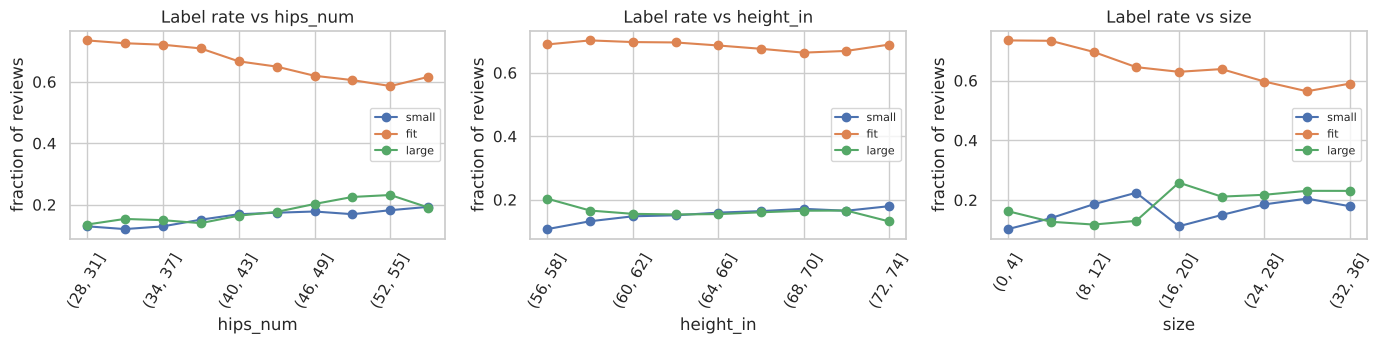

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, col, bins in zip(axes, ["hips_num", "height_in", "size"],
                         [np.arange(28, 60, 3), np.arange(56, 76, 2), np.arange(0, 40, 4)]):
    rates = pd.crosstab(pd.cut(train[col], bins), train["fit"], normalize="index")[CLASSES]
    rates.plot(ax=ax, marker="o"); ax.set_title(f"Label rate vs {col}"); ax.set_xlabel(col)
    ax.set_ylabel("fraction of reviews"); ax.tick_params(axis="x", rotation=60); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

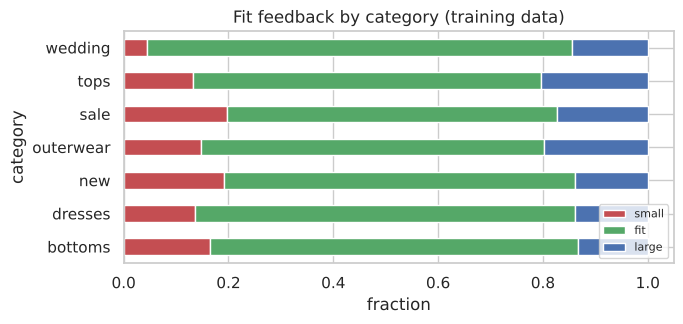

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.4))
pd.crosstab(train["category"], train["fit"], normalize="index")[CLASSES].plot.barh(
    stacked=True, ax=ax, color=["#C44E52", "#55A868", "#4C72B0"])
ax.set_title("Fit feedback by category (training data)"); ax.set_xlabel("fraction")
ax.legend(loc="lower right", fontsize=8); plt.tight_layout(); plt.show()

### Customers are consistent, and so are items (training data)
If customers had no systematic tendencies, a customer's *other* reviews would tell us nothing about this one. Below, for each training review we compute the fraction of the **same customer's other reviews** (and the **same item's other reviews**) that said "small". Both are predictive of the current label. Customers whose other reviews all said "small" say "small" twice as often (27% vs 13.5%). The effect is even stronger for items: if most of an item's other reviews said "small", 40–50% of its remaining reviews say so too, vs. 9% for items with none. This is exactly the structure that user/item bias terms and latent factors can exploit.

In [9]:
def leave_one_out_rate(frame, key, cls):
    """For each row: fraction of the OTHER rows with the same key whose label is `cls` (NaN if no others)."""
    g = frame.groupby(key)["fit"]
    tot = g.transform("size"); hits = g.transform(lambda s: (s == cls).sum())
    own = (frame["fit"] == cls).astype(int)
    return ((hits - own) / (tot - 1)).where(tot > 1)

for key in ["user_id", "item_id"]:
    loo = leave_one_out_rate(train, key, "small")
    print(f"\nLabel distribution, grouped by the fraction of OTHER reviews by the same {key} that said 'small':")
    display(pd.crosstab(pd.cut(loo, [-0.01, 0, .25, .5, .75, 1.0]), train["fit"], normalize="index")[CLASSES].round(3))


Label distribution, grouped by the fraction of OTHER reviews by the same user_id that said 'small':


fit,small,fit,large
fit,,,
"(-0.01, 0.0]",0.135,0.704,0.161
"(0.0, 0.25]",0.153,0.685,0.162
"(0.25, 0.5]",0.202,0.641,0.157
"(0.5, 0.75]",0.210,0.632,0.158
"(0.75, 1.0]",0.267,0.598,0.135



Label distribution, grouped by the fraction of OTHER reviews by the same item_id that said 'small':


fit,small,fit,large
fit,,,
"(-0.01, 0.0]",0.089,0.616,0.295
"(0.0, 0.25]",0.119,0.717,0.164
"(0.25, 0.5]",0.309,0.582,0.109
"(0.5, 0.75]",0.492,0.403,0.105
"(0.75, 1.0]",0.380,0.497,0.123


### The leakage problem in one table
`length` is filled in *by the reviewer at the same time* as `fit`. When length is "very short", 59% of fit labels are "small". It is highly predictive, but only because it is effectively a second answer to the same question. Hence the Setting A / Setting B separation.

In [10]:
pd.crosstab(train["length"], train["fit"], normalize="index")[CLASSES].round(3)

fit,small,fit,large
length,,,
just right,0.141,0.736,0.123
slightly long,0.117,0.554,0.328
slightly short,0.339,0.587,0.074
very long,0.113,0.389,0.497
very short,0.587,0.337,0.076


---
<a id="sec3"></a>
# 3. Modeling

**ML formulation.** Ordinal 3-class classification. Each model outputs probabilities $\hat p(y\mid u, p, x)$ for $y\in\{\text{small},\text{fit},\text{large}\}$, where $u$ is the customer, $p$ the product (item × size) and $x$ the customer's measurements. Probabilistic models are trained by minimizing a (regularized) negative log-likelihood. We build up from trivial to more expressive models:

| # | Model | Uses | Course concepts |
|---|---|---|---|
| B0 | Always "fit" | – | trivial baseline |
| B1 | Random by class prior | – | trivial baseline |
| B2 | Product's smoothed empirical label distribution | product | popularity / additive smoothing |
| M1 | Multinomial logistic regression | x | classification, regularization |
| M1b | Logistic regression with balanced class weights | x | class imbalance |
| M2 | Logistic regression + one-hot user / item / product | x, u, p | bias terms |
| M3 | **Ordinal true-size model** (1-LV, Sembium et al.) | u, p | latent factor model, ordinal regression |
| M4 | **Hybrid ordinal model (ours):** + measurements + fit tolerance + K latent factors | u, p, x | latent factors with side information |
| M5 | Gradient-boosted trees with out-of-fold target statistics | x, aggregates of u, p | non-course comparison point |
| M6 | Unweighted average of M2, M4, M5 | – | ensembling |
| Bt / Btl | TF-IDF logistic regression on review text (+ length, quality, ids) | review | **Setting B upper bound** |

### Shared evaluation utilities
* `avg_auc`: the primary metric.
* `tune_weights`: turns probabilities into labels. It multiplies the probabilities by per-class weights $(w_\text{small}, 1, w_\text{large})$ and takes the argmax, choosing the weights that maximize macro-F1 **on validation**. Without this, most models would almost never predict the rare classes.
* `ber`: balanced error rate (lower is better).
* `evaluate`: computes all test metrics for one model and stores them in `results`.

In [11]:
def avg_auc(y, P):
    """Primary metric: one-vs-rest ROC AUC for each of the 3 classes, averaged."""
    return np.mean([roc_auc_score(y == k, P[:, k]) for k in range(3)])

def ber(y, yhat):
    """Balanced error rate: mean over classes of (1 - recall) = 1 - balanced accuracy. Naive 3-class = 2/3."""
    return 1.0 - balanced_accuracy_score(y, yhat)

def tune_weights(y, P, grid=np.linspace(0.5, 4.0, 15)):
    """Choose class multipliers (w_small, 1, w_large) maximizing macro-F1 of argmax(P * w) on (y, P)."""
    best = (-1, (1, 1, 1))
    for ws in grid:
        for wl in grid:
            w = np.array([ws, 1.0, wl])
            f = f1_score(y, (P * w).argmax(1), average="macro")
            if f > best[0]: best = (f, tuple(w))
    return np.array(best[1])

def evaluate(name, Pv, Pt, setting="A"):
    """Tune the decision weights on validation probs Pv, then score test probs Pt. Returns test label predictions."""
    w = tune_weights(yv, Pv)
    yhat = (Pt * w).argmax(1)
    results[name] = dict(setting=setting,
                         avg_AUC=avg_auc(yt, Pt),
                         AUC_small=roc_auc_score(yt == 0, Pt[:, 0]),
                         AUC_fit=roc_auc_score(yt == 1, Pt[:, 1]),
                         AUC_large=roc_auc_score(yt == 2, Pt[:, 2]),
                         macro_F1=f1_score(yt, yhat, average="macro"),
                         BER=ber(yt, yhat),
                         accuracy=accuracy_score(yt, yhat),
                         val_avg_AUC=avg_auc(yv, Pv))
    r = results[name]
    print(f"{name:<40s} test avgAUC={r['avg_AUC']:.4f}  macroF1={r['macro_F1']:.4f}  BER={r['BER']:.4f}  acc={r['accuracy']:.4f}")
    return yhat

results, preds_test, probs_test, chosen = {}, {}, {}, {}   # chosen = selected hyperparameters per model
yv, yt = val["y"].values, test["y"].values

### B0, B1: trivial baselines
B0 always predicts "fit" and B1 guesses at random following the training class distribution. Neither has any ranking ability (AUC = 0.5 by construction), and both sit at the naive BER of ⅔. B0 shows how deceptively "good" accuracy can look.

In [12]:
prior = np.bincount(train["y"], minlength=3) / len(train)
rng = np.random.default_rng(SEED)
for name, yhat in [("B0 Always 'fit'", np.ones(len(test), int)),
                   ("B1 Random by class prior", rng.choice(3, size=len(test), p=prior))]:
    results[name] = dict(setting="A", avg_AUC=0.5, AUC_small=0.5, AUC_fit=0.5, AUC_large=0.5,
                         macro_F1=f1_score(yt, yhat, average="macro"), BER=ber(yt, yhat),
                         accuracy=accuracy_score(yt, yhat), val_avg_AUC=0.5)
    preds_test[name[:2]] = yhat
    r = results[name]
    print(f"{name:<40s} macroF1={r['macro_F1']:.4f}  BER={r['BER']:.4f}  acc={r['accuracy']:.4f}")

B0 Always 'fit'                          macroF1=0.2711  BER=0.6667  acc=0.6855
B1 Random by class prior                 macroF1=0.3434  BER=0.6566  acc=0.5281


### B2: the product's smoothed empirical label distribution
This is what shoppers do when they read "runs small" in the reviews. We estimate $\hat p(y\mid \text{product})$ by counting training labels, smoothed toward the parent item's distribution, which is itself smoothed toward the global prior $\pi$ (additive / Dirichlet smoothing):
$$\hat p(y\mid p) = \frac{n_{p,y} + \alpha\,\hat p(y\mid i)}{n_p + \alpha},\qquad \hat p(y\mid i) = \frac{n_{i,y} + \beta\,\pi_y}{n_i + \beta}.$$
Unseen products fall back to their item, and unseen items to the prior. $\alpha,\beta$ are tuned on validation.

In [13]:
def smoothed_rates(tr, alpha, beta):
    """Return (item-level, product-level) smoothed label distributions estimated on `tr`."""
    Y = np.eye(3)[tr["y"].values]
    it = pd.DataFrame(Y, index=tr["item_id"].values).groupby(level=0).sum()
    pr = pd.DataFrame(Y, index=tr["product"].values).groupby(level=0).sum()
    item_rate = (it + beta * prior).div(it.sum(1) + beta, axis=0)
    prod_item = tr.drop_duplicates("product").set_index("product")["item_id"]
    base = item_rate.loc[prod_item.loc[pr.index].values].values
    prod_rate = pd.DataFrame((pr.values + alpha * base) / (pr.values.sum(1, keepdims=True) + alpha), index=pr.index)
    return item_rate, prod_rate

def predict_rates(frame, item_rate, prod_rate):
    """Product estimate if the product was seen, else item estimate, else the global prior."""
    P = np.tile(prior, (len(frame), 1))
    ii = frame["item_id"].isin(item_rate.index).values
    P[ii] = item_rate.loc[frame["item_id"].values[ii]].values
    pp = frame["product"].isin(prod_rate.index).values
    P[pp] = prod_rate.loc[frame["product"].values[pp]].values
    return P

best = None
for a in [1, 3, 10, 30]:
    for b in [3, 10, 30, 100]:
        s = avg_auc(yv, predict_rates(val, *smoothed_rates(train, a, b)))
        if best is None or s > best[0]: best = (s, a, b)
chosen["B2"] = f"alpha={best[1]}, beta={best[2]}"
print(f"selected {chosen['B2']}  (val avgAUC={best[0]:.4f})")
rates_ = smoothed_rates(train, best[1], best[2])
P2v, P2t = predict_rates(val, *rates_), predict_rates(test, *rates_)
preds_test["B2"] = evaluate("B2 Product empirical rate", P2v, P2t); probs_test["B2"] = P2t

selected alpha=30, beta=10  (val avgAUC=0.7109)
B2 Product empirical rate                test avgAUC=0.7080  macroF1=0.4938  BER=0.5066  acc=0.6280


### Features for the linear models
* **Dense block:** standardized numeric measurements (and `size`) + one missing-indicator per column.
* **Sparse block:** one-hot `category` and `shoe width`.
* **Id block (M2 only):** one-hot `user_id`, `item_id`, `product`. Ids not seen in training map to an all-zero vector, so for cold-start customers the model automatically falls back to the feature-based prediction.

In [14]:
med = train[NUM].median()
scaler = StandardScaler().fit(train[NUM].fillna(med))

def dense_block(frame):
    """Standardized numeric features (median-imputed) + missing indicators."""
    return np.hstack([scaler.transform(frame[NUM].fillna(med)), frame[NUM].isna().values.astype(float)])

ohe_cat = OneHotEncoder(handle_unknown="ignore").fit(train[["category", "shoe_width"]])
ohe_ids = OneHotEncoder(handle_unknown="ignore").fit(train[["user_id", "item_id", "product"]])

def features(frame, ids=False):
    """Sparse design matrix: dense block + categorical one-hots (+ id one-hots if ids=True)."""
    blocks = [sparse.csr_matrix(dense_block(frame)), ohe_cat.transform(frame[["category", "shoe_width"]])]
    if ids: blocks.append(ohe_ids.transform(frame[["user_id", "item_id", "product"]]))
    return sparse.hstack(blocks).tocsr()

Xtr_a, Xv_a, Xt_a = features(train), features(val), features(test)
Xtr_b, Xv_b, Xt_b = features(train, True), features(val, True), features(test, True)
print(f"M1 features: {Xtr_a.shape[1]} | M2 features (with id one-hots): {Xtr_b.shape[1]:,}")

M1 features: 27 | M2 features (with id one-hots): 47,049


### M1 / M2: multinomial logistic regression
**M1** uses only measurements and category: does body shape alone predict fit? **M2** adds one-hot ids, which is equivalent to learning a **bias per customer, per item and per product** for each class. This is the course's $\alpha + \beta_u + \beta_i$ idea, placed inside a softmax. The L2 strength (sklearn's $C$, where smaller means stronger regularization) is tuned on validation.

*Trade-offs.* Convex and fast, with a unique optimum. But M2 ignores the ordering of the labels: it learns separate, unrelated parameters for "small" and "large", which wastes data in a sparse setting.

In [15]:
def fit_lr(Xtr, Xv, Cs, key):
    """Fit multinomial LR for each C, keep the one with the best validation average AUC."""
    best = None
    for C in Cs:
        m = LogisticRegression(C=C, max_iter=2000).fit(Xtr, train["y"])
        s = avg_auc(yv, m.predict_proba(Xv))
        print(f"   C={C:<5} val avgAUC={s:.4f}")
        if best is None or s > best[0]: best = (s, C, m)
    chosen[key] = f"C={best[1]}"
    return best[2]

print("M1 (measurements only):"); m1 = fit_lr(Xtr_a, Xv_a, [0.01, 0.1, 1.0], "M1")
probs_test["M1"] = m1.predict_proba(Xt_a)
preds_test["M1"] = evaluate("M1 LogReg (measurements)", m1.predict_proba(Xv_a), probs_test["M1"])
print("M2 (+ user/item/product one-hots):"); m2 = fit_lr(Xtr_b, Xv_b, [0.03, 0.1, 0.3, 1.0], "M2")
probs_test["M2"] = m2.predict_proba(Xt_b)
preds_test["M2"] = evaluate("M2 LogReg + id biases", m2.predict_proba(Xv_b), probs_test["M2"])

M1 (measurements only):
   C=0.01  val avgAUC=0.5781
   C=0.1   val avgAUC=0.5774
   C=1.0   val avgAUC=0.5774
M1 LogReg (measurements)                 test avgAUC=0.5819  macroF1=0.3876  BER=0.6120  acc=0.5594
M2 (+ user/item/product one-hots):
   C=0.03  val avgAUC=0.7047
   C=0.1   val avgAUC=0.7185
   C=0.3   val avgAUC=0.7256
   C=1.0   val avgAUC=0.7231
M2 LogReg + id biases                    test avgAUC=0.7216  macroF1=0.5138  BER=0.4778  acc=0.6301


### M1b: the class-imbalance problem, and class weights as a first fix
*This step comes from our team's first exploration (Saaketh's `eda` branch).*

If we take a plain logistic regression and simply predict the most probable class (argmax), the 69% majority wins almost every time: the model predicts "fit" for nearly every review. It matches the always-"fit" baseline's accuracy while catching almost no misfits, so its BER sits near the naive ⅔. A standard fix is `class_weight="balanced"`, which re-weights the training loss so that mistakes on the rare "small"/"large" classes cost as much in total as mistakes on "fit". The model then predicts the minority classes far more often.

Below we compare three ways of turning M1's measurement features into labels:
1. plain LR + argmax;
2. class-balanced LR + argmax (**M1b**);
3. plain LR + our validation-tuned decision weights (`tune_weights`, which every other model in this notebook uses).

Options 2 and 3 attack the same problem from different ends: re-weighting the *training*, or re-weighting the *decision*.

In [16]:
m1b = LogisticRegression(C=m1.C, class_weight="balanced", max_iter=2000).fit(Xtr_a, train["y"])
chosen["M1b"] = f"C={m1.C} (same as M1), class_weight='balanced'"
w_m1 = tune_weights(yv, m1.predict_proba(Xv_a))
story_preds = {"1. plain LR, argmax": m1.predict(Xt_a),
               "2. class-balanced LR, argmax (M1b)": m1b.predict(Xt_a),
               "3. plain LR + validation-tuned decision weights (M1)": (m1.predict_proba(Xt_a) * w_m1).argmax(1)}
story = pd.DataFrame({name: {"share predicted 'fit'": np.mean(yh == 1),
                             "recall small": np.mean(yh[yt == 0] == 0), "recall large": np.mean(yh[yt == 2] == 2),
                             "macro-F1": f1_score(yt, yh, average="macro"), "BER": ber(yt, yh),
                             "accuracy": accuracy_score(yt, yh)} for name, yh in story_preds.items()}).T
display(pretty(story, precision=3))

# M1b also goes through the standard evaluation, so it appears in the main results table
probs_test["M1b"] = m1b.predict_proba(Xt_a)
preds_test["M1b"] = evaluate("M1b LogReg, class-balanced", m1b.predict_proba(Xv_a), probs_test["M1b"])

,share predicted 'fit',recall small,recall large,macro-F1,BER,accuracy
"1. plain LR, argmax",1.000,0.000,0.000,0.271,0.667,0.685
"2. class-balanced LR, argmax (M1b)",0.374,0.425,0.389,0.354,0.595,0.403
3. plain LR + validation-tuned decision weights (M1),0.683,0.207,0.244,0.388,0.612,0.559


M1b LogReg, class-balanced               test avgAUC=0.5809  macroF1=0.3776  BER=0.6240  acc=0.5846


**Reading the comparison.**
* **Plain LR + argmax predicts "fit" for 100% of test reviews.** It catches no misfits at all, so its accuracy (68.5%) equals the always-"fit" baseline and its BER is the naive 0.667. This is the imbalance problem in its purest form.
* **Balanced class weights fix it.** M1b predicts "fit" for only 37% of reviews and catches about 40% of the small and large cases, giving the **lowest BER of the three (0.595)**. This matches the ≈40% balanced accuracy found in our first exploration. The cost is accuracy, which falls to 40%: re-weighting the loss makes the model over-predict the rare classes.
* **Tuned decision weights land in between** and get the **best macro-F1 (0.388)**. They are tuned for macro-F1, just as class weights implicitly target balanced accuracy, so each fix wins on the metric it aims at.
* **The ranking barely changes:** M1 and M1b have almost identical AUC (0.582 vs. 0.581, see the main table). Re-weighting mostly moves the decision boundary rather than teaching the model anything new. Fixing the *decision* is not the same as finding more *signal*. For that we need customer and product information (M2 onward), not class weights.

We keep validation-tuned decision weights as the default for all later models, because they leave training untouched and can be applied identically to every model. M1b stays in the results table as a reference point.

### M3 / M4: ordinal "true-size" latent factor models

Fit is **ordinal**, and it has a physical interpretation: a product feels *large* when its true size exceeds the customer's true size. Following Sembium et al. (2017) and Misra et al. (2018), we learn a single scalar **fit score** per (customer, product) pair:

$$ z_{u,p} = \underbrace{b_{\text{item}(p)} + e_p + \gamma\cdot\text{size}_p}_{\text{product true size}} \;-\; \underbrace{\big(a_u + \mathbf{w}^\top \mathbf{x}_u\big)}_{\text{customer true size}} \;+\; \underbrace{\langle \mathbf{U}_u, \mathbf{V}_p\rangle}_{K\text{-dim fit semantics}} $$

and map it to the three classes with an **ordinal (cumulative) logit** with learned thresholds $\theta_1<\theta_2$:
$$P(\text{small}) = \sigma(\theta_1 - z),\qquad P(\text{small or fit}) = \sigma(\theta_2 - z),\qquad P(\text{large}) = 1-\sigma(\theta_2 - z).$$
A large positive $z$ (product much bigger than the customer) pushes probability toward "large", and a large negative $z$ toward "small".

* **M3: classic true-size model (1-LV, as in Sembium et al.).** Only the id terms $a_u, b_i, e_p$ and the size slope $\gamma$. One latent "true size" per customer and per product.
* **M4: our hybrid.** Three additions:
  1. **Measurements** $\mathbf{w}^\top\mathbf{x}_u$: the customer's true size is partly *predicted from their body*, so cold-start customers are not all treated as average.
  2. **Fit tolerance** $\tau_{u,p} = \tau_u + \tau_{\text{item}} + \tau_p$ widens or narrows the "fit" window, so the thresholds become $\theta_1 - \tau_{u,p}$ and $\theta_2 + \tau_{u,p}$. A stretchy wrap dress fits a wide range of bodies ($\tau > 0$), while a picky customer or a structured blazer has a narrow window ($\tau < 0$). A pure shift model **cannot** express "this product gets unusually many *fit* labels". This turned out to be M3's main weakness: its AUC on the "fit" class lags logistic regression by ≈0.06 (see `AUC_fit` in the results table).
  3. **$K$-dimensional latent factors** $\langle\mathbf{U}_u,\mathbf{V}_p\rangle$ for multi-dimensional fit, e.g. "long-waisted customer × dress cut short in the torso" (Misra et al.'s *fit semantics*).

**Training.** We minimize the mean negative log-likelihood plus L2 penalties ($\lambda_\text{bias}, \lambda_w, \lambda_\text{lat}, \lambda_\text{tol}$) with **full-batch Adam**. The gradients are derived by hand in `OrdinalTrueSize.grads` and checked against finite differences below. The number of Adam steps acts as early stopping and is tuned on validation along with $K$ and the regularizers. Parameters for ids unseen in training are treated as 0.

**Why add features to a latent factor model at all?** The course's content-and-structure lecture notes that with enough interactions per user and item, latent factors make explicit features unnecessary. It names two situations where that argument breaks down: **cold start** (too few interactions) and **interpretability**. ModCloth is squarely in both: two-thirds of customers have a single review, and a size model is only useful if its parameters mean something.

**Trade-offs vs. M2.** It needs fewer parameters (one score per pair instead of one per class), its parameters are interpretable (sizes and tolerances), and it respects the label order. On the downside, it is non-convex once $K>0$ (results depend on initialization and the stopping point), it needs a custom implementation, and its customer-specific terms do nothing for the ≈44% of test reviews written by unseen customers. That last point is why the measurement term matters.

In [17]:
class OrdinalTrueSize:
    """Ordinal (cumulative-logit) true-size model.

    K       : number of latent fit-semantics dimensions (0 = none)
    use_x   : include the measurement term w^T x_u in the customer's true size
    tol     : include the fit-tolerance terms tau_u + tau_item + tau_p
    lam_*   : L2 strengths for biases / latent factors / measurement weights / tolerances
    lr, iters : Adam step size and number of full-batch steps
    """
    def __init__(self, K=0, use_x=True, tol=False, lam_bias=1.0, lam_lat=5.0, lam_w=0.1, lam_tol=3.0,
                 lr=0.05, iters=500, seed=SEED):
        self.K, self.use_x, self.tol = K, use_x, tol
        self.lam_bias, self.lam_lat, self.lam_w, self.lam_tol = lam_bias, lam_lat, lam_w, lam_tol
        self.lr, self.iters, self.seed = lr, iters, seed

    # ---- indexing: map raw ids to parameter rows (-1 = unseen in training) -------------------
    def _index(self, frame, fit=False):
        if fit:
            self.u_ix = {v: j for j, v in enumerate(frame["user_id"].unique())}
            self.i_ix = {v: j for j, v in enumerate(frame["item_id"].unique())}
            self.p_ix = {v: j for j, v in enumerate(frame["product"].unique())}
        m = lambda col, d: frame[col].map(d).fillna(-1).astype(int).values
        return m("user_id", self.u_ix), m("item_id", self.i_ix), m("product", self.p_ix)

    # ---- model -------------------------------------------------------------------------------
    def _z(self, P, u, i, p, X, size):
        """Fit score z = product true size - customer true size + <U_u, V_p>. Unseen ids contribute 0."""
        uu, ii, pp = np.maximum(u, 0), np.maximum(i, 0), np.maximum(p, 0)
        z = P["g"][0] * size + (i >= 0) * P["b"][ii] + (p >= 0) * P["e"][pp] - (u >= 0) * P["a"][uu]
        if self.use_x: z = z - X @ P["w"]
        if self.K > 0: z = z + ((u >= 0) & (p >= 0)) * np.sum(P["U"][uu] * P["V"][pp], axis=1)
        return z

    def _tau(self, P, u, i, p):
        """Fit tolerance: > 0 widens the 'fit' window, < 0 narrows it."""
        if not self.tol: return 0.0
        return ((u >= 0) * P["tu"][np.maximum(u, 0)] + (i >= 0) * P["ti"][np.maximum(i, 0)]
                + (p >= 0) * P["tp"][np.maximum(p, 0)])

    @staticmethod
    def _probs(P, z, tau=0.0):
        """Cumulative logit. theta_2 = theta_1 + exp(.) guarantees theta_1 < theta_2."""
        t1, t2 = P["th"][0] - tau, P["th"][0] + np.exp(P["th"][1]) + tau
        s1, s2 = 1 / (1 + np.exp(-(t1 - z))), 1 / (1 + np.exp(-(t2 - z)))
        return np.clip(np.stack([s1, s2 - s1, 1 - s2], 1), 1e-12, 1), s1, s2

    # ---- objective and its gradient --------------------------------------------------------
    def grads(self, P, idx, X, size, y):
        """Return (mean NLL + L2 penalty, dict of exact gradients for every parameter block).

        With s1 = sigma(t1 - z), s2 = sigma(t2 - z) and L = -log p_y:
          y=small: dL/dz = 1 - s1,             dL/dt1 = -(1 - s1),   dL/dt2 = 0
          y=fit  : dL/dz = (d2 - d1)/p_fit,    dL/dt1 = d1/p_fit,    dL/dt2 = -d2/p_fit   (d = s(1-s))
          y=large: dL/dz = -s2,                dL/dt1 = 0,           dL/dt2 = s2
        Chain rule then distributes dL/dz to every term of z, and dL/dt1, dL/dt2 to theta and tau.
        """
        u, i, p = idx; n = len(y)
        z = self._z(P, u, i, p, X, size)
        pr, s1, s2 = self._probs(P, z, self._tau(P, u, i, p))
        d1, d2, pm = s1 * (1 - s1), s2 * (1 - s2), pr[:, 1]
        dz  = np.select([y == 0, y == 1], [1 - s1, (d2 - d1) / pm], -s2)
        gt1 = np.select([y == 0, y == 1], [-(1 - s1), d1 / pm], 0.0)
        gt2 = np.select([y == 0, y == 1], [0.0, -d2 / pm], s2)
        nll = -np.mean(np.log(pr[np.arange(n), y]))
        reg = (self.lam_bias * (P["a"] @ P["a"] + P["b"] @ P["b"] + P["e"] @ P["e"]) + self.lam_w * P["w"] @ P["w"]
               + (self.lam_lat * (np.sum(P["U"] ** 2) + np.sum(P["V"] ** 2)) if self.K > 0 else 0)
               + (self.lam_tol * (P["tu"] @ P["tu"] + P["ti"] @ P["ti"] + P["tp"] @ P["tp"]) if self.tol else 0)) / (2 * n)
        G = {"g": np.array([dz @ size]) / n,
             "b": (np.bincount(i, dz, len(P["b"])) + self.lam_bias * P["b"]) / n,
             "e": (np.bincount(p, dz, len(P["e"])) + self.lam_bias * P["e"]) / n,
             "a": (-np.bincount(u, dz, len(P["a"])) + self.lam_bias * P["a"]) / n,
             "w": (-(X.T @ dz) + self.lam_w * P["w"]) / n if self.use_x else np.zeros_like(P["w"]),
             "th": np.array([np.sum(gt1 + gt2), np.sum(gt2) * np.exp(P["th"][1])]) / n,
             "U": np.zeros_like(P["U"]), "V": np.zeros_like(P["V"]),
             "tu": np.zeros_like(P["tu"]), "ti": np.zeros_like(P["ti"]), "tp": np.zeros_like(P["tp"])}
        if self.tol:                       # t1 = th0 - tau, t2 = th0 + exp(th1) + tau  =>  dL/dtau = dL/dt2 - dL/dt1
            dtau = gt2 - gt1
            G["tu"] = (np.bincount(u, dtau, len(P["tu"])) + self.lam_tol * P["tu"]) / n
            G["ti"] = (np.bincount(i, dtau, len(P["ti"])) + self.lam_tol * P["ti"]) / n
            G["tp"] = (np.bincount(p, dtau, len(P["tp"])) + self.lam_tol * P["tp"]) / n
        if self.K > 0:
            np.add.at(G["U"], u, dz[:, None] * P["V"][p]); np.add.at(G["V"], p, dz[:, None] * P["U"][u])
            G["U"] = G["U"] / n + self.lam_lat * P["U"] / n; G["V"] = G["V"] / n + self.lam_lat * P["V"] / n
        return nll + reg, G

    def init_params(self, X):
        """Zeros for biases/tolerances, small random latent factors, thresholds at the class-prior logits."""
        rng = np.random.default_rng(self.seed); K = max(self.K, 1)
        return dict(a=np.zeros(len(self.u_ix)), b=np.zeros(len(self.i_ix)), e=np.zeros(len(self.p_ix)),
                    g=np.zeros(1), w=np.zeros(X.shape[1]), th=np.array([-1.7, np.log(3.4)]),
                    U=rng.normal(0, 0.1, (len(self.u_ix), K)), V=rng.normal(0, 0.1, (len(self.p_ix), K)),
                    tu=np.zeros(len(self.u_ix)), ti=np.zeros(len(self.i_ix)), tp=np.zeros(len(self.p_ix)))

    # ---- training / prediction -------------------------------------------------------------
    def fit(self, frame, X, size, monitor=None, every=25):
        """Full-batch Adam. If `monitor(model)` is given, record (step, train loss, monitor value) every `every` steps."""
        idx = self._index(frame, fit=True); y = frame["y"].values
        self.P = P = self.init_params(X)
        M = {k: np.zeros_like(v) for k, v in P.items()}; S = {k: np.zeros_like(v) for k, v in P.items()}
        self.history = []
        for t in range(1, self.iters + 1):
            loss, G = self.grads(P, idx, X, size, y)
            for k in P:                                   # Adam update (in place)
                M[k] = 0.9 * M[k] + 0.1 * G[k]; S[k] = 0.999 * S[k] + 0.001 * G[k] ** 2
                P[k] -= self.lr * (M[k] / (1 - 0.9 ** t)) / (np.sqrt(S[k] / (1 - 0.999 ** t)) + 1e-8)
            if monitor is not None and t % every == 0:
                self.history.append((t, loss, monitor(self)))
        return self

    def predict_proba(self, frame, X, size):
        u, i, p = self._index(frame)
        return self._probs(self.P, self._z(self.P, u, i, p, X, size), self._tau(self.P, u, i, p))[0]

# Customer-side features x_u: standardized measurements (the product's size is NOT a customer feature) + missing flags
XU_COLS = [c for c in NUM if c != "size"]
def user_x(frame):
    Z = (frame[XU_COLS].fillna(med[XU_COLS]) - med[XU_COLS]) / train[XU_COLS].std()
    return np.hstack([Z.values, frame[XU_COLS].isna().values.astype(float)])
size_mu, size_sd = train["size"].mean(), train["size"].std()
s_tr, s_v, s_t = [(f["size"].values - size_mu) / size_sd for f in (train, val, test)]
XU_tr, XU_v, XU_t = user_x(train), user_x(val), user_x(test)

**Gradient check.** Before trusting a hand-derived gradient, we compare it with a central finite difference $\frac{L(\theta+\epsilon)-L(\theta-\epsilon)}{2\epsilon}$ on a random 400-review sample, for at least one parameter from every block, with all model components switched on. Agreement to ~1e-10 means the derivation above is correct.

In [18]:
small = train.sample(400, random_state=1)
Xs, ss = user_x(small), (small["size"].values - size_mu) / size_sd
gm = OrdinalTrueSize(K=2, tol=True, lam_bias=0.5, lam_lat=0.5, lam_w=0.5)
idx = gm._index(small, fit=True); ys = small["y"].values
rng = np.random.default_rng(0)
Pg = {k: v + rng.normal(0, 0.05, v.shape) for k, v in gm.init_params(Xs).items()}   # a random, non-trivial point
_, G = gm.grads(Pg, idx, Xs, ss, ys)
rows = []
for name, j in [("w", 0), ("w", 4), ("g", 0), ("th", 0), ("th", 1), ("a", 3), ("b", 1), ("e", 5),
                ("U", 7), ("V", 3), ("tu", 2), ("ti", 1), ("tp", 4)]:
    flat = Pg[name].reshape(-1); base = flat[j]; eps = 1e-6
    flat[j] = base + eps; lp, _ = gm.grads(Pg, idx, Xs, ss, ys)
    flat[j] = base - eps; lm, _ = gm.grads(Pg, idx, Xs, ss, ys)
    flat[j] = base
    rows.append(dict(parameter=f"{name}[{j}]", analytic=G[name].reshape(-1)[j], numeric=(lp - lm) / (2 * eps)))
gc_df = pd.DataFrame(rows); gc_df["abs_error"] = (gc_df.analytic - gc_df.numeric).abs()
print(f"max absolute error: {gc_df.abs_error.max():.1e}")
gc_df

max absolute error: 1.0e-10


,parameter,analytic,numeric,abs_error
0,w[0],1.555e-02,1.555e-02,6.691e-11
1,w[4],1.500e-03,1.500e-03,2.465e-11
2,g[0],-2.850e-02,-2.850e-02,2.478e-12
3,th[0],-2.117e-02,-2.117e-02,3.067e-11
4,th[1],-9.237e-02,-9.237e-02,3.290e-11
5,a[3],2.033e-03,2.033e-03,5.666e-11
6,b[1],-1.488e-03,-1.488e-03,4.841e-11
7,e[5],1.257e-04,1.257e-04,9.991e-11
8,U[7],-2.065e-04,-2.065e-04,9.519e-12
9,V[3],8.844e-05,8.844e-05,1.492e-12


**M3: classic true-size model (no measurements, no tolerance, K=0).** We tune the bias regularizer and the number of Adam steps on validation.

In [19]:
best = None
for lam in [0.3, 1.0, 3.0]:
    for iters in [150, 250, 500]:
        m = OrdinalTrueSize(K=0, use_x=False, lam_bias=lam, iters=iters).fit(train, XU_tr, s_tr)
        s = avg_auc(yv, m.predict_proba(val, XU_v, s_v))
        print(f"   lam_bias={lam:<4} iters={iters:<4} val avgAUC={s:.4f}")
        if best is None or s > best[0]: best = (s, f"lam_bias={lam}, iters={iters}", m)
m3 = best[2]; chosen["M3"] = best[1]
P3v, P3t = m3.predict_proba(val, XU_v, s_v), m3.predict_proba(test, XU_t, s_t)
preds_test["M3"] = evaluate("M3 Ordinal true-size (1-LV)", P3v, P3t); probs_test["M3"] = P3t

   lam_bias=0.3  iters=150  val avgAUC=0.6788
   lam_bias=0.3  iters=250  val avgAUC=0.6788
   lam_bias=0.3  iters=500  val avgAUC=0.6788
   lam_bias=1.0  iters=150  val avgAUC=0.6872
   lam_bias=1.0  iters=250  val avgAUC=0.6872
   lam_bias=1.0  iters=500  val avgAUC=0.6872
   lam_bias=3.0  iters=150  val avgAUC=0.6841
   lam_bias=3.0  iters=250  val avgAUC=0.6841
   lam_bias=3.0  iters=500  val avgAUC=0.6841
M3 Ordinal true-size (1-LV)              test avgAUC=0.6793  macroF1=0.4988  BER=0.4974  acc=0.6210


**M4: our hybrid (true size + measurements + fit tolerance + K latent factors).** We tune $K$ (with its regularizer), the tolerance regularizer and the number of Adam steps on validation: 12 configurations.

In [20]:
best, t0 = None, time.time()
for K, lam_lat in [(0, 1.0), (2, 10.0), (5, 10.0)]:
    for lam_tol in [3.0, 10.0]:
        for iters in [250, 500]:
            m = OrdinalTrueSize(K=K, use_x=True, tol=True, lam_bias=1.0, lam_lat=lam_lat,
                                lam_tol=lam_tol, iters=iters).fit(train, XU_tr, s_tr)
            s = avg_auc(yv, m.predict_proba(val, XU_v, s_v))
            print(f"   K={K} lam_lat={lam_lat:<4} lam_tol={lam_tol:<4} iters={iters:<4} val avgAUC={s:.4f}")
            if best is None or s > best[0]: best = (s, f"K={K}, lam_lat={lam_lat}, lam_tol={lam_tol}, iters={iters}", m)
m4 = best[2]; chosen["M4"] = best[1]
print(f"selected {chosen['M4']}  (search took {time.time() - t0:.0f}s)")
P4v, P4t = m4.predict_proba(val, XU_v, s_v), m4.predict_proba(test, XU_t, s_t)
preds_test["M4"] = evaluate("M4 Hybrid ordinal (ours)", P4v, P4t); probs_test["M4"] = P4t

   K=0 lam_lat=1.0  lam_tol=3.0  iters=250  val avgAUC=0.7289
   K=0 lam_lat=1.0  lam_tol=3.0  iters=500  val avgAUC=0.7289
   K=0 lam_lat=1.0  lam_tol=10.0 iters=250  val avgAUC=0.7272
   K=0 lam_lat=1.0  lam_tol=10.0 iters=500  val avgAUC=0.7272
   K=2 lam_lat=10.0 lam_tol=3.0  iters=250  val avgAUC=0.7289
   K=2 lam_lat=10.0 lam_tol=3.0  iters=500  val avgAUC=0.7289
   K=2 lam_lat=10.0 lam_tol=10.0 iters=250  val avgAUC=0.7272
   K=2 lam_lat=10.0 lam_tol=10.0 iters=500  val avgAUC=0.7272
   K=5 lam_lat=10.0 lam_tol=3.0  iters=250  val avgAUC=0.7289
   K=5 lam_lat=10.0 lam_tol=3.0  iters=500  val avgAUC=0.7289
   K=5 lam_lat=10.0 lam_tol=10.0 iters=250  val avgAUC=0.7272
   K=5 lam_lat=10.0 lam_tol=10.0 iters=500  val avgAUC=0.7272
selected K=2, lam_lat=10.0, lam_tol=3.0, iters=500  (search took 64s)
M4 Hybrid ordinal (ours)                 test avgAUC=0.7221  macroF1=0.5170  BER=0.4702  acc=0.6239


**Training dynamics of M4.** We retrain the selected configuration for 1,000 steps while monitoring validation AUC, to check that training has converged and is not overfitting. Full-batch Adam converges within ≈150 steps, after which both the training loss and the validation AUC are flat (the small blip near step 870 is a transient Adam oscillation). With the chosen L2 penalties the model does **not** drift into overfitting, so the exact step count is not critical.

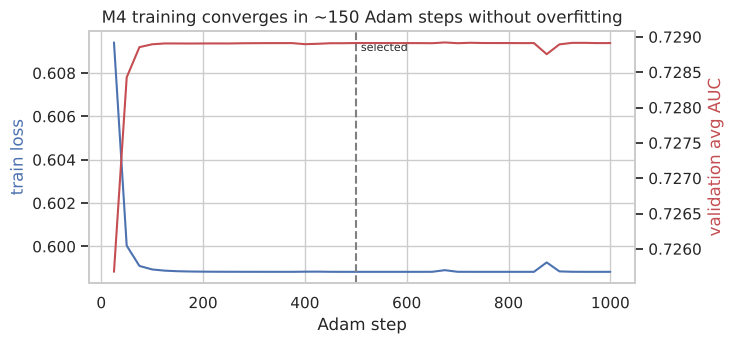

In [21]:
curve = OrdinalTrueSize(K=m4.K, use_x=True, tol=True, lam_bias=1.0, lam_lat=m4.lam_lat, lam_tol=m4.lam_tol,
                        iters=1000).fit(train, XU_tr, s_tr, monitor=lambda mm: avg_auc(yv, mm.predict_proba(val, XU_v, s_v)))
h = np.array(curve.history)
fig, ax1 = plt.subplots(figsize=(7.5, 3.6))
ax1.plot(h[:, 0], h[:, 1], color="#4C72B0", label="train loss (NLL + L2)"); ax1.set_xlabel("Adam step")
ax1.set_ylabel("train loss", color="#4C72B0")
ax2 = ax1.twinx(); ax2.plot(h[:, 0], h[:, 2], color="#C44E52", label="validation avg AUC")
ax2.set_ylabel("validation avg AUC", color="#C44E52"); ax2.grid(False)
ax1.axvline(m4.iters, ls="--", c="gray"); ax1.text(m4.iters + 10, h[:, 1].max(), "selected", fontsize=8, va="top")
ax1.set_title("M4 training converges in ~150 Adam steps without overfitting"); plt.tight_layout(); plt.show()

### M5: gradient-boosted trees (non-course comparison point)
Can a flexible non-linear model match the latent factor models? `HistGradientBoostingClassifier` gets the measurements, size and category, plus **target statistics**: the smoothed fraction of "small" and "large" labels for the review's customer, item and product, and how many training reviews each has. To avoid leakage, these statistics are computed **out-of-fold** for the training rows (5 folds, so no row ever sees its own label) and from the full training set for validation and test rows.

*Trade-offs.* Trees handle missing values and non-linear interactions natively and train in seconds. However, target statistics are a hand-crafted summary of the customer, and the model has no notion of a customer's "true size" or of label order.

In [22]:
def target_stats(tr, ap, keys=("user_id", "item_id", "product"), smooth=5):
    """Smoothed small/large rates and counts per key, estimated on `tr`, looked up for rows of `ap`."""
    out = {}
    for key in keys:
        Y = pd.DataFrame(np.eye(3)[tr["y"].values], columns=CLASSES); Y[key] = tr[key].values
        g = Y.groupby(key)[CLASSES].agg(["sum", "count"]); cnt = g[("small", "count")]
        for c in ["small", "large"]:
            k = CLASSES.index(c)
            out[f"{key}_{c}_rate"] = ap[key].map((g[(c, "sum")] + smooth * prior[k]) / (cnt + smooth)).fillna(prior[k]).values
        out[f"{key}_n"] = ap[key].map(cnt).fillna(0).values
    return pd.DataFrame(out, index=ap.index)

oof = pd.DataFrame(index=train.index)
for trn_ix, oof_ix in KFold(5, shuffle=True, random_state=SEED).split(train):
    ts = target_stats(train.iloc[trn_ix], train.iloc[oof_ix]); oof.loc[ts.index, ts.columns] = ts
cat_codes = {c: i for i, c in enumerate(sorted(df["category"].unique()))}
def gb_frame(frame, stats):
    D = frame[NUM].copy(); D["category"] = frame["category"].map(cat_codes)
    return pd.concat([D, stats], axis=1)
G_tr = gb_frame(train, oof.astype(float))
G_v, G_t = gb_frame(val, target_stats(train, val)), gb_frame(test, target_stats(train, test))
best = None
for lr_ in [0.05, 0.1]:
    gb = HistGradientBoostingClassifier(learning_rate=lr_, max_iter=400, early_stopping=True, random_state=SEED,
                                        categorical_features=[G_tr.columns.get_loc("category")]).fit(G_tr, train["y"])
    s = avg_auc(yv, gb.predict_proba(G_v)); print(f"   learning_rate={lr_} val avgAUC={s:.4f}")
    if best is None or s > best[0]: best = (s, lr_, gb)
m5 = best[2]; chosen["M5"] = f"learning_rate={best[1]}, early stopping at {m5.n_iter_} trees"
probs_test["M5"] = m5.predict_proba(G_t)
preds_test["M5"] = evaluate("M5 Gradient boosting + target stats", m5.predict_proba(G_v), probs_test["M5"])

   learning_rate=0.05 val avgAUC=0.7291
   learning_rate=0.1 val avgAUC=0.7262
M5 Gradient boosting + target stats      test avgAUC=0.7250  macroF1=0.5176  BER=0.4711  acc=0.6286


### M6: simple ensemble
M2, M4 and M5 make different kinds of errors: M4 is ordinal and uses measurements, M2 learns unconstrained per-class biases, and M5 learns non-linear interactions. An **unweighted average** of their probabilities has no parameters to fit, so it cannot overfit the validation set.

In [23]:
P6v = (m2.predict_proba(Xv_b) + P4v + m5.predict_proba(G_v)) / 3
probs_test["M6"] = (probs_test["M2"] + probs_test["M4"] + probs_test["M5"]) / 3
preds_test["M6"] = evaluate("M6 Ensemble (avg of M2, M4, M5)", P6v, probs_test["M6"]); chosen["M6"] = "none (plain average)"

M6 Ensemble (avg of M2, M4, M5)          test avgAUC=0.7270  macroF1=0.5184  BER=0.4789  acc=0.6414


### Setting B: what if we could read the review? (leaky upper bound)
**Bt:** TF-IDF of unigrams and bigrams over summary + text, then multinomial logistic regression. **Btl:** the same plus one-hot `length` and `quality` and the M2 features. About 8% of reviews have no text, so for those the text features are empty.

In [24]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=100_000, sublinear_tf=True)
T_tr, T_v, T_t = tfidf.fit_transform(train["text"]), tfidf.transform(val["text"]), tfidf.transform(test["text"])
ohe_len = OneHotEncoder(handle_unknown="ignore").fit(train[["length", "quality"]].astype(str))
def text_plus(T, frame, X):
    """TF-IDF block + length/quality one-hots + M2 features."""
    return sparse.hstack([T, ohe_len.transform(frame[["length", "quality"]].astype(str)), X]).tocsr()

mt = LogisticRegression(C=3.0, max_iter=3000).fit(T_tr, train["y"])
probs_test["Bt"] = mt.predict_proba(T_t)
preds_test["Bt"] = evaluate("Bt TF-IDF text LogReg", mt.predict_proba(T_v), probs_test["Bt"], setting="B")
mtl = LogisticRegression(C=3.0, max_iter=3000).fit(text_plus(T_tr, train, Xtr_b), train["y"])
probs_test["Btl"] = mtl.predict_proba(text_plus(T_t, test, Xt_b))
preds_test["Btl"] = evaluate("Btl text + length + quality + ids", mtl.predict_proba(text_plus(T_v, val, Xv_b)),
                             probs_test["Btl"], setting="B")
chosen["Bt / Btl"] = "C=3.0 (fixed)"

Bt TF-IDF text LogReg                    test avgAUC=0.8543  macroF1=0.6786  BER=0.3495  acc=0.7903
Btl text + length + quality + ids        test avgAUC=0.8731  macroF1=0.6948  BER=0.3148  acc=0.7861


**What does the text model look at?** The largest coefficients show that Setting B mostly reads the customer's explicit verdict ("runs small", "too big", "size up"), which confirms that this is label leakage rather than real prediction.

In [25]:
vocab = np.array(tfidf.get_feature_names_out())
top = {c: vocab[np.argsort(-mt.coef_[k])[:12]] for k, c in enumerate(CLASSES)}
pd.DataFrame(top)

,small,fit,large
0,tight,perfect,big
1,small,perfectly,large
2,snug,not too,baggy
3,bit small,true to,loose
4,size up,great,little large
5,smaller than,fits perfectly,huge
6,little small,flattering,smaller size
7,tighter than,comfortable,size down
8,too small,just right,down
9,small side,and fit,little big


---
<a id="sec4"></a>
# 4. Evaluation

**Protocol recap.** Every model was fit on the training split. Every hyperparameter (and the macro-F1 decision weights) was chosen on validation. The numbers below are on the **test split**, which was not used for any decision. The `val_avg_AUC` column lets us check for overfitting to validation: validation and test agree closely for all models.

### Main results

In [26]:
R = pd.DataFrame(results).T[["setting", "avg_AUC", "AUC_small", "AUC_fit", "AUC_large", "macro_F1", "BER", "accuracy", "val_avg_AUC"]]
R[R.columns[1:]] = R[R.columns[1:]].astype(float)
pretty(R, gradient=["avg_AUC", "macro_F1"])  # BER: lower is better

,setting,avg_AUC,AUC_small,AUC_fit,AUC_large,macro_F1,BER,accuracy,val_avg_AUC
B0 Always 'fit',A,0.5000,0.5000,0.5000,0.5000,0.2711,0.6667,0.6855,0.5000
B1 Random by class prior,A,0.5000,0.5000,0.5000,0.5000,0.3434,0.6566,0.5281,0.5000
B2 Product empirical rate,A,0.7080,0.7281,0.6635,0.7324,0.4938,0.5066,0.6280,0.7109
M1 LogReg (measurements),A,0.5819,0.5890,0.5678,0.5890,0.3876,0.6120,0.5594,0.5781
M2 LogReg + id biases,A,0.7216,0.7405,0.6764,0.7479,0.5138,0.4778,0.6301,0.7256
"M1b LogReg, class-balanced",A,0.5809,0.5829,0.5682,0.5916,0.3776,0.6240,0.5846,0.5751
M3 Ordinal true-size (1-LV),A,0.6793,0.7186,0.6174,0.7020,0.4988,0.4974,0.6210,0.6872
M4 Hybrid ordinal (ours),A,0.7221,0.7440,0.6754,0.7468,0.5170,0.4702,0.6239,0.7289
M5 Gradient boosting + target stats,A,0.7250,0.7468,0.6780,0.7504,0.5176,0.4711,0.6286,0.7291
"M6 Ensemble (avg of M2, M4, M5)",A,0.7270,0.7479,0.6805,0.7526,0.5184,0.4789,0.6414,0.7322


**Selected hyperparameters** (all chosen on validation):

In [27]:
pd.DataFrame.from_dict(chosen, orient="index", columns=["selected on validation"])

,selected on validation
B2,"alpha=30, beta=10"
M1,C=0.01
M2,C=0.3
M1b,"C=0.01 (same as M1), class_weight='balanced'"
M3,"lam_bias=1.0, iters=500"
M4,"K=2, lam_lat=10.0, lam_tol=3.0, iters=500"
M5,"learning_rate=0.05, early stopping at 111 trees"
M6,none (plain average)
Bt / Btl,C=3.0 (fixed)


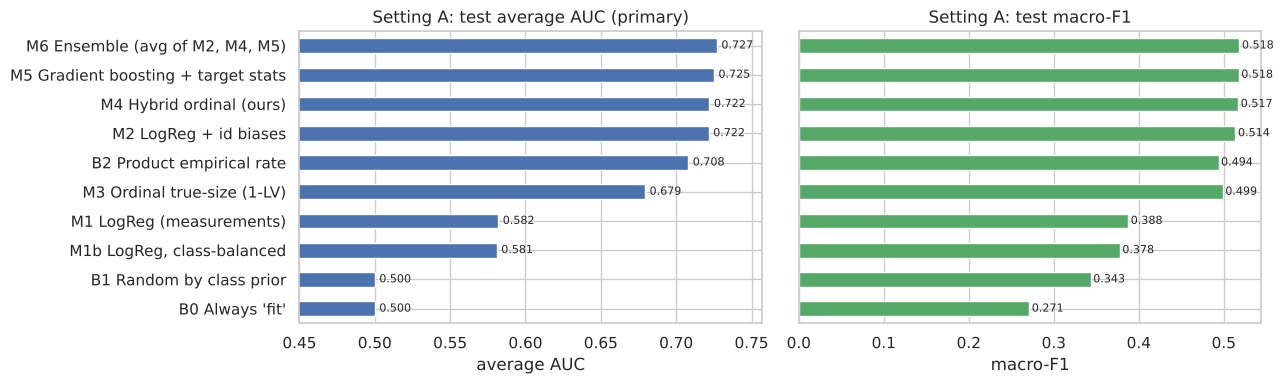

In [28]:
RA = R[R.setting == "A"].sort_values("avg_AUC")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
RA["avg_AUC"].plot.barh(ax=axes[0], color="#4C72B0"); axes[0].set_xlim(0.45, RA.avg_AUC.max() + .03)
axes[0].set_title("Setting A: test average AUC (primary)"); axes[0].set_xlabel("average AUC")
RA["macro_F1"].plot.barh(ax=axes[1], color="#55A868"); axes[1].set_title("Setting A: test macro-F1")
axes[1].set_xlabel("macro-F1"); axes[1].set_yticklabels([])
for ax, col in zip(axes, ["avg_AUC", "macro_F1"]):
    for yi, v in enumerate(RA[col]): ax.text(v + 0.003, yi, f"{v:.3f}", va="center", fontsize=8)
plt.tight_layout(); plt.show()

**Reading the table.**
* B0 ("always fit") has the **highest accuracy** of any pre-purchase model (68.6%), yet the worst macro-F1, the naive BER of 0.667 and no ranking ability. This is exactly why accuracy is not our metric: real models deliberately predict small/large more often, trading some accuracy for macro-F1.
* Measurements alone (M1, M1b) are weak, with or without class weights. The real signal is **who** is buying **what**: B2, M2, M4, M5 and M6, which all exploit customer and/or product identity, reach ≈0.71–0.73.
* The classic true-size model (M3) is *worse* than simply counting labels per product (B2). The `AUC_fit` column shows why: M3 is weakest at recognizing the "fit" class (0.617 vs. 0.676 for M2), because a single shift parameter cannot express that some products just fit most people. Our M4 additions close that gap and bring it level with the strongest baselines.
* By **BER**, our M4 has the lowest error of any pre-purchase model (0.470), essentially tied with M5 (0.471). The ensemble's BER is a little higher (0.479) because its decision weights were tuned for macro-F1, not BER: the two metrics reward slightly different trade-offs between the classes.
* Setting B is in a different league (≈0.85–0.87) because it reads the answer from the review.

### Is the difference real? Paired bootstrap
We draw 300 bootstrap resamples of the 8,279 test reviews. For each resample we compute average AUC for two models **on the same resample** and record the difference. A 95% interval that excludes 0 means the gap is unlikely to be noise.

In [29]:
rng = np.random.default_rng(SEED); n = len(yt); B = 300
boot_ix = [rng.integers(0, n, n) for _ in range(B)]
rows = []
for a, b in [("M4", "B2"), ("M4", "M1"), ("M4", "M3"), ("M4", "M2"), ("M4", "M5"), ("M6", "M2"), ("M6", "M4"), ("M6", "M5")]:
    diffs = np.array([avg_auc(yt[ix], probs_test[a][ix]) - avg_auc(yt[ix], probs_test[b][ix]) for ix in boot_ix])
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    rows.append(dict(comparison=f"{a} − {b}", mean_diff=diffs.mean(), ci_low=lo, ci_high=hi,
                     verdict=("significant" if lo > 0 or hi < 0 else "tie (CI contains 0)")))
pretty(pd.DataFrame(rows).set_index("comparison"))

,mean_diff,ci_low,ci_high,verdict
comparison,,,,
M4 − B2,0.0142,0.0089,0.0190,significant
M4 − M1,0.1400,0.1279,0.1522,significant
M4 − M3,0.0427,0.0360,0.0488,significant
M4 − M2,0.0006,-0.0023,0.0035,tie (CI contains 0)
M4 − M5,-0.0029,-0.0069,0.0008,tie (CI contains 0)
M6 − M2,0.0054,0.0036,0.0072,significant
M6 − M4,0.0048,0.0032,0.0067,significant
M6 − M5,0.0020,-0.0004,0.0042,tie (CI contains 0)


* M4 is significantly better than B2, M1 and M3, and statistically tied with M2 and M5.
* The ensemble M6 is significantly better than M2 and M4 (+0.005 AUC: small but real), but its edge over the boosted trees M5 is within noise.
* Practical reading: on this data a well-regularized simple model is as good as a custom one; the value of M4 lies in its **interpretability** (next subsections) as much as in its score.

### ROC curves for the two misfit classes
The ROC curve shows the whole trade-off between catching misfits (true positive rate) and false alarms, rather than the single operating point that macro-F1 picks. The dashed curve (Setting B) shows how far the honest pre-purchase models are from the leaky upper bound.

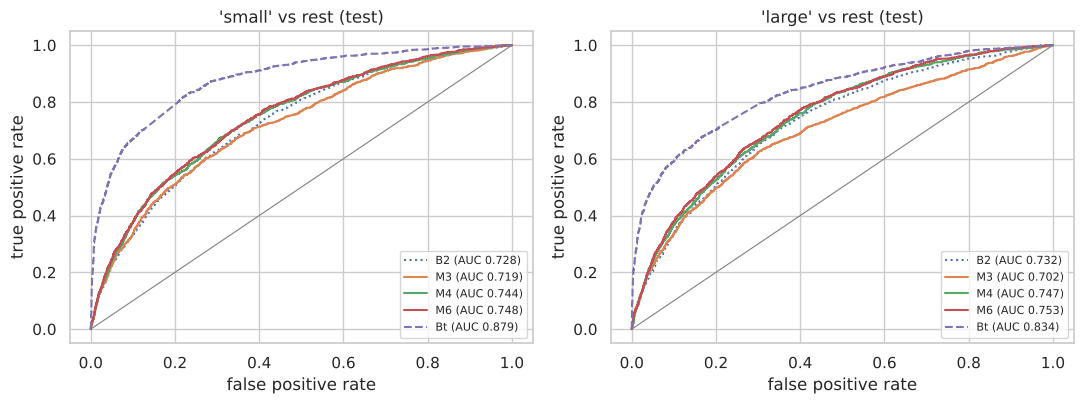

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, k in zip(axes, [0, 2]):
    for key, style in [("B2", ":"), ("M3", "-"), ("M4", "-"), ("M6", "-"), ("Bt", "--")]:
        fpr, tpr, _ = roc_curve(yt == k, probs_test[key][:, k])
        ax.plot(fpr, tpr, style, label=f"{key} (AUC {roc_auc_score(yt == k, probs_test[key][:, k]):.3f})")
    ax.plot([0, 1], [0, 1], c="gray", lw=0.8)
    ax.set_title(f"'{CLASSES[k]}' vs rest (test)"); ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate")
    ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

### Cold-start vs. returning customers
About 44% of test reviews (3,623 of 8,279) are written by customers with **no** training reviews. For them, customer-specific parameters are useless, and models must rely on the product side and (for M1/M4) measurements. Breaking results down by history shows where each model's accuracy comes from.

,n_test,B2,M1,M2,M3,M4,M5,M6
customer history,,,,,,,,
cold (0 train reviews),3623,0.7111,0.5871,0.7118,0.6729,0.7128,0.7179,0.7170
1–2 train reviews,2745,0.7035,0.5786,0.7199,0.6826,0.7230,0.7250,0.7273
3+ train reviews,1911,0.7085,0.5807,0.7408,0.6877,0.7367,0.7380,0.7435


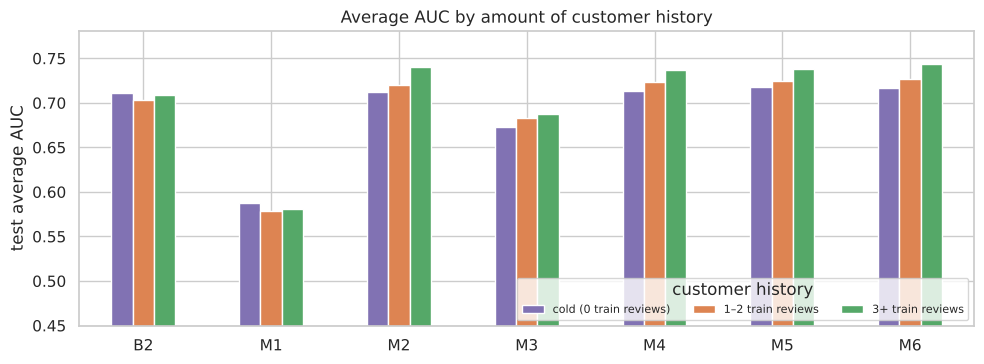

In [31]:
ntrain = test["user_id"].map(train["user_id"].value_counts()).fillna(0)
groups = pd.cut(ntrain, [-1, 0, 2, 1000], labels=["cold (0 train reviews)", "1–2 train reviews", "3+ train reviews"])
rows = []
for g in groups.cat.categories:
    ix = (groups == g).values
    rows.append({"customer history": g, "n_test": int(ix.sum()),
                 **{k: avg_auc(yt[ix], probs_test[k][ix]) for k in ["B2", "M1", "M2", "M3", "M4", "M5", "M6"]}})
cold = pd.DataFrame(rows).set_index("customer history")
display(pretty(cold))
cold.drop(columns="n_test").T.plot.bar(figsize=(10, 3.8), rot=0, color=["#8172B3", "#DD8452", "#55A868"])
plt.ylabel("test average AUC"); plt.title("Average AUC by amount of customer history"); plt.ylim(0.45, None)
plt.legend(title="customer history", loc="lower right", ncol=3, fontsize=8); plt.tight_layout(); plt.show()

Every collaborative model improves with more customer history, as expected. B2 is flat because it ignores the customer. Even for cold customers, M4 is ≈0.04 AUC above M3. Product-side knowledge, tolerance and measurements carry most of the cold-start performance.

### Fairness: does the model work equally well for larger body sizes?
The course's ethics lecture uses **this dataset** as a case study. Wan, Ni, Misra & McAuley (WSDM 2020) show that ModCloth customers whose body type differs from the one a product is *marketed* with get worse recommendations. The lecture frames fairness in recommendation as **some groups getting less utility (higher error)** than others. Our own EDA found that larger sizes receive more misfit complaints, so the natural question is whether our models are also less accurate for these customers (**error parity**).

Our version of the data has no explicit body-type label (the WSDM 2020 version does), so we use two proxies:
* **Purchased size ≥ 20** (top ≈22% of ModCloth's 0–38 size scale) vs. smaller sizes, available for every review.
* **Self-reported bra band ≥ 38** vs. ≤ 36, for the ≈93% of reviews that report it.

For each group we report its size, its observed misfit rate, the model's *predicted* misfit rate (is the problem under-estimated?), and AUC / macro-F1 / BER. The decision weights are the ones tuned on the whole validation set, as a deployed system would use them. A paired bootstrap gives a 95% interval for the AUC and BER gaps between the groups.

In [32]:
groupings = {
    "purchased size": np.where(test["size"].values >= 20, "size 20+", "size under 20"),
    "bra band (self-reported)": np.where(test["bra_size_num"].isna(), "missing",
                                         np.where(test["bra_size_num"].values >= 38, "band 38+", "band 36 or less")),
}
rows = []
for grouping, labels in groupings.items():
    for gname in sorted(set(labels) - {"missing"}, key=lambda g: ("+" in g, g)):   # smaller group first
        ix = labels == gname
        row = {"grouping": grouping, "group": gname, "n_test": int(ix.sum()),
               "observed misfit rate": float(np.mean(yt[ix] != 1)),
               "M6 predicted misfit rate": float(np.mean(1 - probs_test["M6"][ix, 1]))}
        for k in ["B2", "M2", "M4", "M6"]:
            row[f"{k} AUC"] = avg_auc(yt[ix], probs_test[k][ix])
        row["M6 macro-F1"] = f1_score(yt[ix], preds_test["M6"][ix], average="macro")
        row["M6 BER"] = ber(yt[ix], preds_test["M6"][ix])
        rows.append(row)
fair = pd.DataFrame(rows).set_index(["grouping", "group"])
display(pretty(fair, precision=3))

# Paired bootstrap of the gap (larger group minus the rest), reusing the resamples from the significance test
gap_rows = []
for grouping, (big, rest) in {"purchased size": ("size 20+", "size under 20"),
                              "bra band (self-reported)": ("band 38+", "band 36 or less")}.items():
    labels = groupings[grouping]
    for k in ["M4", "M6"]:
        d_auc, d_ber = [], []
        for ix in boot_ix:
            lb, yb, pb, hb = labels[ix], yt[ix], probs_test[k][ix], preds_test[k][ix]
            a, b = lb == big, lb == rest
            d_auc.append(avg_auc(yb[a], pb[a]) - avg_auc(yb[b], pb[b]))
            d_ber.append(ber(yb[a], hb[a]) - ber(yb[b], hb[b]))
        for metric, d in [("avg AUC", d_auc), ("BER", d_ber)]:
            lo, hi = np.percentile(d, [2.5, 97.5])
            gap_rows.append(dict(grouping=grouping, model=k, metric=metric, gap=np.mean(d), ci_low=lo, ci_high=hi,
                                 verdict="significant" if lo > 0 or hi < 0 else "no clear gap (CI contains 0)"))
print("Gap = larger group minus the rest (AUC: negative = worse for larger sizes; BER: positive = worse):")
pretty(pd.DataFrame(gap_rows).set_index(["grouping", "model", "metric"]), precision=3)

Gap = larger group minus the rest (AUC: negative = worse for larger sizes; BER: positive = worse):


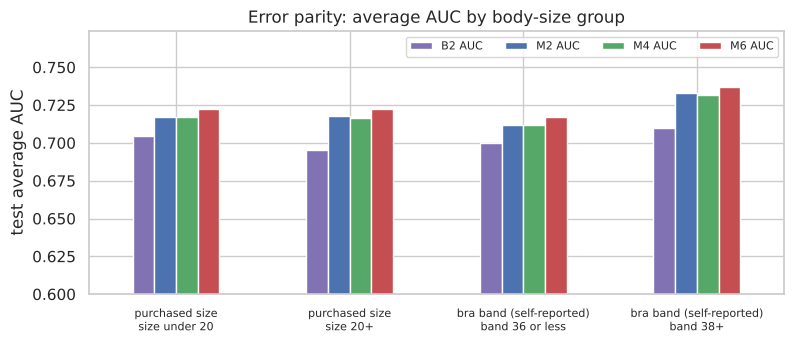

In [33]:
fig, ax = plt.subplots(figsize=(8, 3.6))
fair[[f"{k} AUC" for k in ["B2", "M2", "M4", "M6"]]].plot.bar(ax=ax, rot=0, color=["#8172B3", "#4C72B0", "#55A868", "#C44E52"])
ax.set_xticklabels([f"{g}\n{n}" for g, n in fair.index], fontsize=8); ax.set_xlabel("")
ax.set_ylim(0.6, None); ax.set_ylabel("test average AUC"); ax.legend(fontsize=8, ncol=4, loc="upper right")
ax.set_title("Error parity: average AUC by body-size group"); plt.tight_layout(); plt.show()

**No evidence that the models are less accurate for larger body sizes, but larger-size customers do get more misfits.**
* **Experience differs.** Larger-size purchases are reported as misfits 20–30% more often (38% vs. 30% for size 20+; 36% vs. 30% for band 38+). This matches the ethics lecture's concern that some customers are less well served by the catalog.
* **Ranking quality is equal.** Average AUC differs by at most 0.02 between groups for every model, and no AUC gap is significant.
* **Errors are not worse.** BER is actually *lower* for the larger groups (significantly so for the ensemble, and for M4 by bra band). Because misfits are more common in these groups, the shared decision rule catches more of them.
* **Problems are not under-estimated.** The predicted misfit rate tracks the observed rate in every group (e.g. 0.39 predicted vs. 0.38 observed for size 20+). A size recommender built on these models would therefore *warn* larger-size customers appropriately rather than hide the risk from them.

*Caveats:* size and bra band are only proxies for body type, and a model that is accurate for a group can still leave that group with a worse experience. The disparity here lies in the product range (fit for larger sizes), not in the model's errors.

### Confusion matrices
Rows are normalized (each row sums to 1). The pre-purchase model's errors are mostly "fit" vs. a neighbouring class. It **rarely confuses small with large** (7–9%), which is what we want from an ordinal model, since a small↔large error would mean recommending a size in the wrong direction.

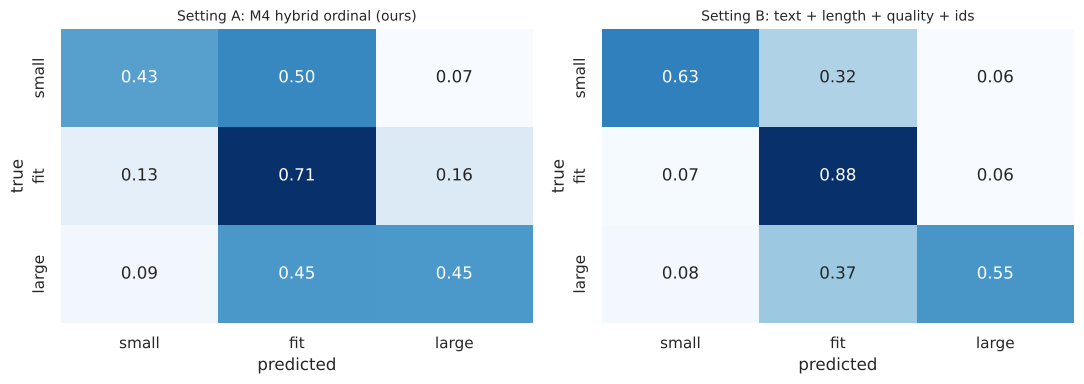

M4 on the test set:
              precision    recall  f1-score   support

       small      0.389     0.429     0.408      1298
         fit      0.765     0.708     0.735      5675
       large      0.371     0.453     0.408      1306

    accuracy                          0.624      8279
   macro avg      0.508     0.530     0.517      8279
weighted avg      0.644     0.624     0.632      8279



In [34]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (k, title) in zip(axes, [("M4", "Setting A: M4 hybrid ordinal (ours)"), ("Btl", "Setting B: text + length + quality + ids")]):
    cm = confusion_matrix(yt, preds_test[k], normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax, cbar=False)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title, fontsize=10)
plt.tight_layout(); plt.show()
print("M4 on the test set:\n" + classification_report(yt, preds_test["M4"], target_names=CLASSES, digits=3))

### Validity check 1: do the learned "true sizes" mean anything?
The model was never told what size numbers mean. If its product parameters really capture size, then:
1. the learned size slope $\gamma$ should be **positive** (a bigger size number makes the item feel larger);
2. within an item, the learned product true size $b_i + e_p + \gamma\,\text{size}_p$ should **increase with the catalog size**;
3. the measurement weights should make bigger bodies have a bigger "customer true size" (positive weights), so items feel *smaller* to them.

1) learned size slope gamma = 0.358  (> 0 as expected)
2) median within-item Spearman correlation (catalog size vs learned true size), 462 items with >= 4 sizes: 0.700;  positive for 89% of items
3) measurement weights (contribution to customer true size, per standard deviation):


,height_in,bra_size_num,bust_num,hips_num,waist_num,shoe_size_num,cup_num
weight,0.058,0.298,-0.011,0.074,0.014,0.029,0.076


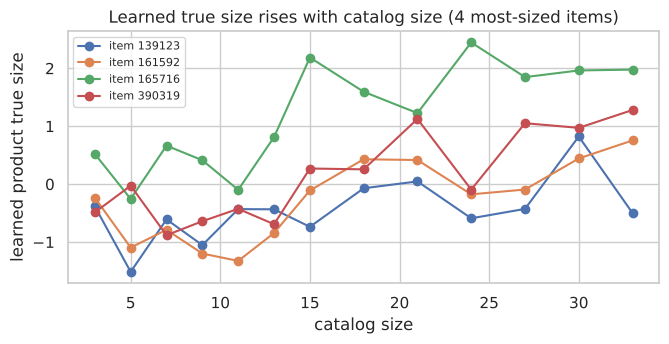

In [35]:
P = m4.P
print(f"1) learned size slope gamma = {P['g'][0]:.3f}  (> 0 as expected)")
inv_p = {v: k for k, v in m4.p_ix.items()}
pt = pd.DataFrame({"product": [inv_p[j] for j in range(len(inv_p))], "e": P["e"]})
pt = pt.join(train.drop_duplicates("product").set_index("product")[["item_id", "size"]], on="product")
pt["true_size"] = (pt["item_id"].map({k: P["b"][v] for k, v in m4.i_ix.items()}) + pt["e"]
                   + P["g"][0] * (pt["size"] - size_mu) / size_sd)
cors = [spearmanr(g["size"], g["true_size"]).correlation for _, g in pt.groupby("item_id") if g["size"].nunique() >= 4]
print(f"2) median within-item Spearman correlation (catalog size vs learned true size), "
      f"{len(cors)} items with >= 4 sizes: {np.nanmedian(cors):.3f};  positive for {np.mean(np.array(cors) > 0):.0%} of items")
print("3) measurement weights (contribution to customer true size, per standard deviation):")
display(pd.DataFrame({"weight": P["w"][:len(XU_COLS)]}, index=XU_COLS).round(3).T)

ex = pt.groupby("item_id").filter(lambda g: len(g) >= 6)["item_id"].value_counts().index[:4]
fig, ax = plt.subplots(figsize=(7, 3.6))
for it in ex:
    g = pt[pt.item_id == it].sort_values("size"); ax.plot(g["size"], g["true_size"], marker="o", label=f"item {it}")
ax.set_xlabel("catalog size"); ax.set_ylabel("learned product true size"); ax.legend(fontsize=8)
ax.set_title("Learned true size rises with catalog size (4 most-sized items)"); plt.tight_layout(); plt.show()

All three checks pass, although the curves are noisy because many sizes have only a handful of reviews. Bra band size dominates the measurement weights; cup size, hips and height have smaller positive weights; bust and waist, which are mostly missing, get ≈0. This makes sense for a store selling mostly dresses and tops, where the bust/band fit is usually the binding constraint.

### Validity check 2: what did the fit tolerance learn?
If $\tau_\text{item}$ captures how *forgiving* an item is, it should correlate with how often the item receives "fit" labels. We also compare categories, keeping items with at least 20 training reviews and categories with at least 5 such items.

In [36]:
inv_i = {v: k for k, v in m4.i_ix.items()}
it_tol = pd.DataFrame({"item_id": [inv_i[j] for j in range(len(inv_i))], "tau_item": P["ti"]})
it_info = train.groupby("item_id").agg(category=("category", lambda s: s.mode()[0]), n=("y", "size"),
                                       frac_fit=("y", lambda s: (s == 1).mean()))
it_tol = it_tol.join(it_info, on="item_id").query("n >= 20")
print(f"correlation(item tolerance, item's fraction of 'fit' labels in training) = "
      f"{it_tol[['tau_item', 'frac_fit']].corr().iloc[0, 1]:.3f}")
cat_tol = it_tol.groupby("category")["tau_item"].agg(mean_tolerance="mean", n_items="count")
cat_tol[cat_tol.n_items >= 5].sort_values("mean_tolerance", ascending=False).round(3)

correlation(item tolerance, item's fraction of 'fit' labels in training) = 0.840


,mean_tolerance,n_items
category,,
bottoms,0.219,52
dresses,0.163,51
tops,0.139,70
new,0.096,70
sale,0.092,17
outerwear,0.070,21


A strong positive correlation confirms that the tolerance learns "forgivingness". By category, bottoms and dresses come out as the most forgiving and outerwear as the least, which is plausible since coats and jackets are more structured. Treat category differences as suggestive only: there are few items per category.

### Calibration
For a size recommender the *probabilities* matter, not just the ranking. The reliability curve for P(small) groups test reviews into 10 bins by predicted probability and compares each bin's mean prediction with the observed frequency. Points on the diagonal mean the probabilities can be taken at face value.

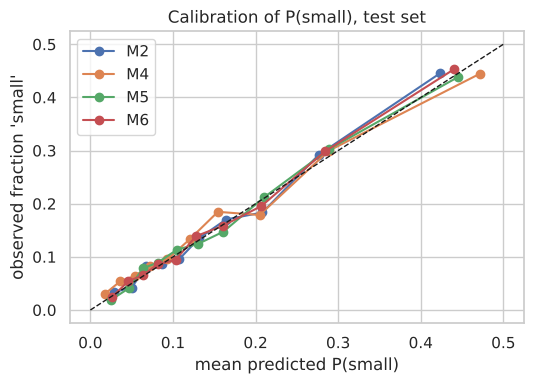

In [37]:
fig, ax = plt.subplots(figsize=(5.5, 4))
for k in ["M2", "M4", "M5", "M6"]:
    p = probs_test[k][:, 0]; edges = np.quantile(p, np.linspace(0, 1, 11)); b = np.digitize(p, edges[1:-1])
    ax.plot([p[b == j].mean() for j in range(10)], [(yt[b == j] == 0).mean() for j in range(10)], marker="o", label=k)
ax.plot([0, .5], [0, .5], "k--", lw=1); ax.set_xlabel("mean predicted P(small)"); ax.set_ylabel("observed fraction 'small'")
ax.set_title("Calibration of P(small), test set"); ax.legend(); plt.tight_layout(); plt.show()

All models are reasonably calibrated. This is expected, because each one is fit by maximum likelihood, and averaging (M6) does not break calibration.

### Ablation of M4
What does each component contribute? We keep the selected hyperparameters, remove one component at a time, retrain, and evaluate on the test set: overall and for cold-start customers only.

In [38]:
base_kw = dict(K=m4.K, use_x=True, tol=True, lam_bias=1.0, lam_lat=m4.lam_lat, lam_tol=m4.lam_tol, iters=m4.iters)
cold_ix = ntrain.values == 0
abl = {}
for name, change in [("full M4", {}),
                     ("− fit tolerance", dict(tol=False)),
                     ("− measurements", dict(use_x=False)),
                     ("− latent factors (K=0)", dict(K=0)),
                     ("− all three (≈ M3)", dict(tol=False, use_x=False, K=0))]:
    m = m4 if not change else OrdinalTrueSize(**{**base_kw, **change}).fit(train, XU_tr, s_tr)
    Pt_ = m.predict_proba(test, XU_t, s_t)
    abl[name] = {"test avg AUC": avg_auc(yt, Pt_), "cold-start avg AUC": avg_auc(yt[cold_ix], Pt_[cold_ix])}
abl = pd.DataFrame(abl).T
abl["Δ vs full"] = abl["test avg AUC"] - abl.loc["full M4", "test avg AUC"]
pretty(abl)

,test avg AUC,cold-start avg AUC,Δ vs full
full M4,0.7221,0.7128,0.0000
− fit tolerance,0.6834,0.6763,-0.0387
− measurements,0.7183,0.7100,-0.0037
− latent factors (K=0),0.7221,0.7128,0.0000
− all three (≈ M3),0.6793,0.6729,-0.0427


**Fit tolerance is the component that matters** (≈ −0.04 AUC without it). Measurements give a small, consistent gain (+0.004, also for cold-start customers). The latent factors contribute nothing measurable: removing them changes AUC only in the fifth decimal, even though validation picked K=2. With a median of 1 review per customer and 2 per product, there is far too little data per pair to learn multi-dimensional fit semantics, so the L2 penalty shrinks the factors to near zero. This differs from Misra et al.'s setting, where the K-dimensional factors were their main improvement.

### Tried and left out: purchase-history features (an idea from our Assignment 1)
In our Assignment 1 rating model (SVD++-style), counting *every known interaction*, including validation/test pairs but never their labels, was a reliable gain. The ModCloth analogue is the customer's **purchase history**. A store knows which items and sizes a customer bought without knowing how they fit, so this is available before any review. From all 82,790 purchases (sizes and ids only, never labels) we built:
* `rel_size`: the purchased size relative to the sizes typically bought for that item (z-score within item);
* the customer's average `rel_size` over their *other* purchases, and the difference between the two ("is she sizing up or down for this item compared with usual?");
* the number of purchases per customer, item and product.

We added them to the boosted-tree model M5 (same settings) and compared validation and test AUC.

In [39]:
item_med = df.groupby("item_id")["size"].median()
item_sd = df.groupby("item_id")["size"].std().fillna(0) + 1.0
rel_all = (df["size"] - df["item_id"].map(item_med)) / df["item_id"].map(item_sd)
u_cnt, u_rel_sum = df.groupby("user_id").size(), rel_all.groupby(df["user_id"]).sum()
p_cnt, i_cnt = df.groupby("product").size(), df.groupby("item_id").size()

def implicit_feats(frame):
    """Purchase-history features from ALL purchases (sizes / ids only, never labels)."""
    rel = rel_all.loc[frame.index]
    n_u = frame["user_id"].map(u_cnt)
    other = (frame["user_id"].map(u_rel_sum) - rel) / (n_u - 1).replace(0, np.nan)   # mean over OTHER purchases
    return pd.DataFrame({"rel_size": rel, "user_other_rel_size": other, "rel_minus_usual": rel - other,
                         "user_n_purchases": n_u, "product_n_purchases": frame["product"].map(p_cnt),
                         "item_n_purchases": frame["item_id"].map(i_cnt)}, index=frame.index)

Gi_tr, Gi_v, Gi_t = [pd.concat([G, implicit_feats(f)], axis=1) for G, f in [(G_tr, train), (G_v, val), (G_t, test)]]
m5i = HistGradientBoostingClassifier(learning_rate=m5.learning_rate, max_iter=400, early_stopping=True, random_state=SEED,
                                     categorical_features=[Gi_tr.columns.get_loc("category")]).fit(Gi_tr, train["y"])
P5i_t = m5i.predict_proba(Gi_t)
tried = pd.DataFrame({
    "val avg AUC": [avg_auc(yv, m5.predict_proba(G_v)), avg_auc(yv, m5i.predict_proba(Gi_v))],
    "test avg AUC": [avg_auc(yt, probs_test["M5"]), avg_auc(yt, P5i_t)],
    "test avg AUC, cold-start": [avg_auc(yt[cold_ix], probs_test["M5"][cold_ix]), avg_auc(yt[cold_ix], P5i_t[cold_ix])]},
    index=["M5", "M5 + purchase-history features"])
pretty(tried)

,val avg AUC,test avg AUC,"test avg AUC, cold-start"
M5,0.7291,0.7250,0.7179
M5 + purchase-history features,0.7314,0.7250,0.7178


**No real gain, so we left these features out.** Validation AUC moves by +0.002, but test AUC is unchanged (0.7250 → 0.7250), and cold-start customers do not benefit either. The likely reason is that the product's own parameters already encode "which size of this item was bought", and two-thirds of customers have no other purchases to learn a habit from. Unlike Goodreads in Assignment 1, there is little interaction history per customer to exploit. This is also a reminder of why we confirm validation gains on the test set before believing them.

### Validity check 3: from fit *prediction* to size *recommendation*
The real use case is counterfactual: *for this customer, which size of this item should they buy?* We score **every size** of the item with the learned true-size gap $z$ and recommend the size whose $z$ is closest to the centre of the fit window, $\tfrac{\theta_1+\theta_2}{2}$.

We have no ground truth for sizes the customer did *not* buy, but there is a directional check. If a test customer said their size ran **small**, a sensible recommender should suggest a **larger** size (and a smaller one if it ran **large**).

In [40]:
mid = m4.P["th"][0] + np.exp(m4.P["th"][1]) / 2           # centre of the fit window (tau shifts both ends equally)
item_sizes = train.groupby("item_id")["size"].unique()

def size_scores(row):
    """Score every catalog size of row's item for row's customer. Returns sizes, z, probabilities."""
    sizes = np.sort(item_sizes[row["item_id"]])
    cand = pd.DataFrame([row] * len(sizes)); cand["size"] = sizes
    cand["product"] = cand["item_id"].astype(str) + "_" + cand["size"].astype(str)
    u, i, p = m4._index(cand); ss = (sizes - size_mu) / size_sd
    return sizes, m4._z(m4.P, u, i, p, user_x(cand), ss), m4.predict_proba(cand, user_x(cand), ss)

agree = []
misfit = test[(test["fit"] != "fit") & test["item_id"].map(lambda i: len(item_sizes.get(i, [])) >= 4)]
for _, r in misfit.iterrows():
    sizes, z, _ = size_scores(r)
    rec = sizes[np.argmin(np.abs(z - mid))]
    if rec != r["size"]: agree.append((rec > r["size"]) == (r["fit"] == "small"))
print(f"misfit test reviews where the recommended size differs from the purchased one: {len(agree):,}")
print(f"recommendation moves in the right direction: {np.mean(agree):.1%}   (chance = 50%)")

r = misfit[misfit["fit"] == "small"].iloc[0]
sizes, z, Pc = size_scores(r)
print(f"\nexample: customer {r['user_id']} bought size {r['size']} of item {r['item_id']} and said it ran '{r['fit']}'")
pretty(pd.DataFrame({"fit score z": z, "P(small)": Pc[:, 0], "P(fit)": Pc[:, 1], "P(large)": Pc[:, 2]},
                    index=pd.Index(sizes, name="size")), precision=3)

misfit test reviews where the recommended size differs from the purchased one: 2,060
recommendation moves in the right direction: 56.8%   (chance = 50%)

example: customer 422877 bought size 8 of item 401773 and said it ran 'small'


,fit score z,P(small),P(fit),P(large)
size,,,,
1,-0.438,0.065,0.882,0.053
4,-1.108,0.085,0.897,0.019
8,-0.681,0.054,0.920,0.027
12,-0.678,0.066,0.901,0.033
15,0.231,0.033,0.872,0.095
20,1.031,0.015,0.804,0.181
26,1.488,0.018,0.571,0.410
32,1.340,0.013,0.715,0.272
38,0.854,0.018,0.823,0.159


**Finding: good fit *prediction* does not automatically give good size *recommendation*.** The model ranks observed (customer, size) pairs well (AUC ≈ 0.72), but it moves the recommendation in the right direction only slightly more often than chance. The reason is **selection bias**, which the course's recommendation lecture calls data that is *missing not at random*: we only observe feedback for the size each customer *chose*, and that choice is not random. each product-size's parameters are learned only from the customers who chose that size, so $e_p$ and $\tau_p$ partly encode *who buys size 26* rather than *how big size 26 is*. The example above shows this: $z$ is not monotone across sizes. The positive $\gamma$ and within-item correlation show that the catalog ordering is partly recovered, but not cleanly enough to extrapolate to sizes the customer never tried. Fixing this would need constraints such as monotone true sizes across an item's sizes, or interventional data (e.g. randomized size suggestions).

---
<a id="sec5"></a>
# 5. Related work & discussion

**The dataset.** ModCloth (together with RentTheRunway) was introduced by **Misra, Wan & McAuley (RecSys 2018)**. They define a *product* as a parent item in a specific size (5,012 products for ModCloth) and evaluate with **average AUC on a random 80:10:10 split**, the same split protocol we use.

**How prior work approached the task.**
* **Sembium et al. (RecSys 2017), Amazon.** One latent "true size" per customer and per product, with the fit score as their difference. Learned with an ordinal loss, then fed to a classifier. Our **M3** follows this idea (Misra et al. call it 1-LV-LR).
* **Misra et al. (RecSys 2018).** Extend this to $K$-dimensional latent variables/factors ("fit semantics", K-LV/K-LF), then use **metric learning with prototyping (LMNN)** to deal with label imbalance. Reported ModCloth average AUC: 1-LV-LR 0.615, K-LV-LR 0.617, K-LF-LR 0.626, K-LV-ML 0.621, **K-LF-ML 0.657**.
* **Sembium et al. (WWW 2018)** propose a Bayesian extension. **Sheikh et al. (RecSys 2019, Zalando)** combine content and collaborative signals in a deep model to handle cold start and sparse orders, the same motivation as our measurement term, and report improvements on the public ModCloth/RentTheRunway data.
* **Baier (2019), "Analyzing Customer Feedback for Product Fit Prediction" (arXiv).** Predicts the fit label *from review text* on ModCloth and RentTheRunway, i.e. our Setting B. On ModCloth: TF-IDF + linear classifier 0.790 micro-F1 (= accuracy), ULMFiT 0.827, BERT 0.811.

**How our results compare.**
* **Same relative story; absolute numbers not comparable.** Like Misra et al., we find the 1-LV true-size model weakest among the collaborative models, with richer models helping. However, *all* our AUCs, including the simple smoothed baseline B2 (0.708), sit above their best result (0.657). Because B2 is so simple, we do **not** read this as "beating the paper". The likely cause is a different AUC protocol: they follow Sembium et al.'s evaluation, which may be computed differently from our one-vs-rest average over 3 classes. Preprocessing (we count 5,005 products vs. their 5,012) and the random split also differ. Comparisons are therefore only meaningful **within our own table**.
* **The improvement that mattered was different.** Misra et al. improve the 1-LV model through multi-dimensional fit semantics and metric learning. In our ablation, latent factors add nothing, measurements add a little, and the **fit tolerance** adds ≈ +0.04 AUC. The pure "shift" model's main failure is that it cannot express that some products and customers simply produce more "fit" labels.
* **Simple models are hard to beat.** Logistic regression with id biases (M2), boosted trees with target statistics (M5) and our M4 are statistically tied, and their ensemble adds only ≈0.002–0.005 AUC. This suggests the remaining pre-purchase signal is small and the labels noisy.
* **Setting B reproduces published work.** Our TF-IDF + logistic regression text model reaches **0.790 accuracy**, matching the 0.790 Baier reports for the same kind of model (with an 80/20 split rather than our 80/10/10). This external agreement is good evidence that our data pipeline is correct. The large Setting A vs. B gap also shows that **most of the predictable signal lives in the post-purchase review**, which a real recommender never sees. Work that mixes the two settings would greatly overstate how well fit can be predicted before purchase.

**Fairness.** Wan, Ni, Misra & McAuley (WSDM 2020), covered in the course's ethics lecture, use a version of ModCloth that records the body type of each product's marketing model. They show that customers buying products not marketed to their body type receive worse recommendations, and that a re-ranking step can restore error parity at little cost. Our data lacks those labels, so we ran a simpler **error-parity check** on body-size proxies (Section 4). We find that larger-size customers experience 20–30% more misfits, but our models rank their outcomes just as well, have no higher error (BER), and predict their elevated misfit risk accurately. In this data the fairness problem is in the product range, not the predictor. A recommender built on these models could even help by flagging items that run small in larger sizes.

**Limitations & future work.**
1. Labels are subjective and noisy ("a bit snug but I like it" may be labelled *fit* or *small*), which caps achievable AUC.
2. Measurements are self-reported and mostly missing.
3. A random split mixes each customer's reviews across train and test. A temporal split would be more realistic, but the dataset has no timestamps.
4. Misra et al.'s metric learning / prototyping could replace our post-hoc class weighting for imbalance.
5. Monotonicity constraints on true size within an item could reduce the selection-bias problem for recommendation.
6. Neural text encoders (e.g. BERT) for Setting B.

**Conclusion.** Accuracy is the wrong metric for this task: "always fit" scores 68.6%. Measured by average AUC, pre-purchase fit prediction is hard but learnable (≈0.72–0.73), while reading the post-purchase review makes it easy (≈0.87), which is a warning about leakage. An **ordinal true-size model with a learned fit tolerance** respects the label order and has interpretable parameters (sizes that track the catalog, items that are forgiving vs. structured). It matches the strongest baselines, and an ensemble with them gives the best pre-purchase model. Turning fit prediction into reliable size *recommendation* remains open, because the feedback suffers from selection bias.

### References
* R. Misra, M. Wan, J. McAuley. *Decomposing Fit Semantics for Product Size Recommendation in Metric Spaces.* RecSys 2018.
* V. Sembium, R. Rastogi, A. Saroop, S. Merugu. *Recommending Product Sizes to Customers.* RecSys 2017.
* V. Sembium, R. Rastogi, L. Tekumalla, A. Saroop. *Bayesian Models for Product Size Recommendations.* WWW 2018.
* A.-S. Sheikh et al. (Zalando). *A Deep Learning System for Predicting Size and Fit in Fashion E-Commerce.* RecSys 2019.
* S. Baier. *Analyzing Customer Feedback for Product Fit Prediction.* arXiv:1908.10896, 2019.
* M. Wan, J. Ni, R. Misra, J. McAuley. *Addressing Marketing Bias in Product Recommendations.* WSDM 2020.